# Statistical Calibration of CMIP6-Based Daily PM2.5 Ensemble Simulations over Fire-Prone Kalimantan, Indonesia

## 1. Setup

In [ ]:
import os, re, sys, zipfile, urllib.request, warnings, logging
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
from matplotlib.patches import FancyBboxPatch, Circle
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image, display

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

DATA_DIR = 'data'
OUT_TAB = os.path.join('outputs', 'tables')
OUT_FIG = os.path.join('outputs', 'figures')
for d in (DATA_DIR, OUT_TAB, OUT_FIG):
    os.makedirs(d, exist_ok=True)

F_PM25 = os.path.join(DATA_DIR, 'pm25_daily_province.csv')
F_COMP = os.path.join(DATA_DIR, 'merra2_pm25_components_daily_province.csv')
F_GADM = os.path.join(DATA_DIR, 'gadm41_IDN_1.json')
F_GADM_SHP = os.path.join(DATA_DIR, 'gadm41_IDN_1.shp')
if 'google.colab' in sys.modules and not (os.path.exists(F_PM25) and os.path.exists(F_COMP)):
    from google.colab import files
    print('Upload pm25_daily_province.csv, merra2_pm25_components_daily_province.csv '
          'and, optionally, the GADM files (gadm41_IDN_1.json, or gadm41_IDN_1.shp/.shx/.dbf/.prj/.cpg).')
    for name in files.upload():
        os.replace(name, os.path.join(DATA_DIR, re.sub(r' \(\d+\)(?=\.[^.]+$)', '', name)))
for f in (F_PM25, F_COMP):
    assert os.path.exists(f), f'{f} not found. Run the notebook from the repository root (current folder: {os.getcwd()}).'
if not os.path.exists(F_GADM) and not os.path.exists(F_GADM_SHP):
    urllib.request.urlretrieve('https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip', F_GADM + '.zip')
    with zipfile.ZipFile(F_GADM + '.zip') as z:
        z.extractall(DATA_DIR)

MODEL = 'MPI-ESM-1-2-HAM'
PROV = ['West Kalimantan', 'Central Kalimantan', 'South Kalimantan', 'East Kalimantan', 'North Kalimantan']
SHORT = {p: p.replace(' Kalimantan', '') for p in PROV}
GADM_NAME = {'KalimantanBarat': 'West Kalimantan', 'KalimantanTengah': 'Central Kalimantan',
             'KalimantanSelatan': 'South Kalimantan', 'KalimantanTimur': 'East Kalimantan',
             'KalimantanUtara': 'North Kalimantan'}
DRY_MONTHS = [6, 7, 8, 9, 10]
STANDARD_24H = 55.0
CATEGORIES = [('Good', 15.5), ('Moderate', 55.4), ('Unhealthy', 150.4), ('Very unhealthy', 250.4), ('Hazardous', np.inf)]
CAT_NAMES = [c[0] for c in CATEGORIES]
CAT_LIMITS = [c[1] for c in CATEGORIES[:-1]]
METHODS = ['Raw', 'VS', 'QDM']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MONTHS_LONG = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August',
               'September', 'October', 'November', 'December']

for fp in ['/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf',
           '/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf']:
    if os.path.exists(fp):
        font_manager.fontManager.addfont(fp)
FONT = next((f for f in ['Arial', 'Liberation Sans', 'DejaVu Sans']
             if f in {x.name for x in font_manager.fontManager.ttflist}), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': FONT, 'font.size': 6.6, 'axes.titlesize': 6.8, 'axes.labelsize': 6.4,
    'xtick.labelsize': 5.8, 'ytick.labelsize': 5.8, 'legend.fontsize': 6, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.5,
    'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2,
    'axes.edgecolor': '#3a3a3a', 'axes.axisbelow': True, 'figure.constrained_layout.use': True,
    'savefig.dpi': 600, 'mathtext.default': 'regular'})
W, H = 3.07, 0.88
COLOR = {'MERRA-2': '#1f1f1f', 'Raw': '#a3a3a3', 'VS': '#d1802e', 'QDM': '#2a6db0'}
LABEL = {'Raw': 'Raw ensemble', 'VS': 'Variance scaling', 'QDM': 'Quantile delta mapping'}
UNIT = 'PM$_{2.5}$ (µg m$^{-3}$)'


def grid(ax, axis='y'):
    ax.grid(axis=axis, color='#e6e6e6', lw=0.4)


def panel_title(ax, letter, text):
    ax.set_title(f'({letter}) {text}', loc='left', pad=2)


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 5, 9]))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(
        lambda v, _: f'{MONTHS[mdates.num2date(v).month - 1]}\n{mdates.num2date(v).year}'))


def save_figure(fig, name):
    path = os.path.join(OUT_FIG, f'{name}.png')
    fig.savefig(path, bbox_inches='tight', pad_inches=0.02)
    plt.close(fig)
    display(Image(filename=path, width=420))


def save_table(df, name, index=True):
    df.to_csv(os.path.join(OUT_TAB, f'{name}.csv'), index=index)
    return df


def date_text(t):
    t = pd.Timestamp(t)
    return f'{t.day} {MONTHS_LONG[t.month - 1]} {t.year}'

## 2. Data

In [ ]:
def season_of(t):
    return np.where(pd.DatetimeIndex(t).month.isin(DRY_MONTHS), 'Dry', 'Wet')


data = pd.read_csv(F_PM25, parse_dates=['date'])
data = data.rename(columns={c: c.split('i')[0] for c in data.columns if c.startswith('r')})
MEMBERS = [c for c in data.columns if c.startswith('r')]
M = len(MEMBERS)
data['month'] = data.date.dt.to_period('M').astype(str)
data['season'] = season_of(data.date)

for d in [data, data[data.merra2.notna()]]:
    assert d.date.nunique() == len(pd.date_range(d.date.min(), d.date.max(), freq='D'))
    assert (d.groupby('date').province.nunique() == len(PROV)).all()
assert (data[MEMBERS] > 0).all().all()

cal = data[data.merra2.notna()].reset_index(drop=True)
proj = data.reset_index(drop=True)
assert (cal.merra2 > 0).all()
START_TARGET = cal.date.max() + pd.Timedelta(days=1)
CAL_MONTHS = sorted(cal.month.unique())
IDEAL_COVERAGE = (M - 1) / (M + 1) * 100

print(f'Model: {MODEL}, members: {MEMBERS}')
print(f'Calibration period: {date_text(cal.date.min())} – {date_text(cal.date.max())} '
      f'({cal.date.nunique()} days, {len(CAL_MONTHS)} months)')
print(f'Projection period : {date_text(START_TARGET)} – {date_text(proj.date.max())}')
print('Days per season (calibration):', cal[cal.province == PROV[0]].season.value_counts().to_dict())
print(f'Ideal coverage of the ensemble range: {IDEAL_COVERAGE:.1f}%')

Model: MPI-ESM-1-2-HAM, members: ['r1', 'r2', 'r3']
Calibration period: 1 January 2025 – 31 August 2026 (608 days, 20 months)
Projection period : 1 September 2026 – 31 January 2027
Days per season (calibration): {'Wet': 363, 'Dry': 245}
Ideal coverage of the ensemble range: 50.0%


## 3. Study Area and Workflow

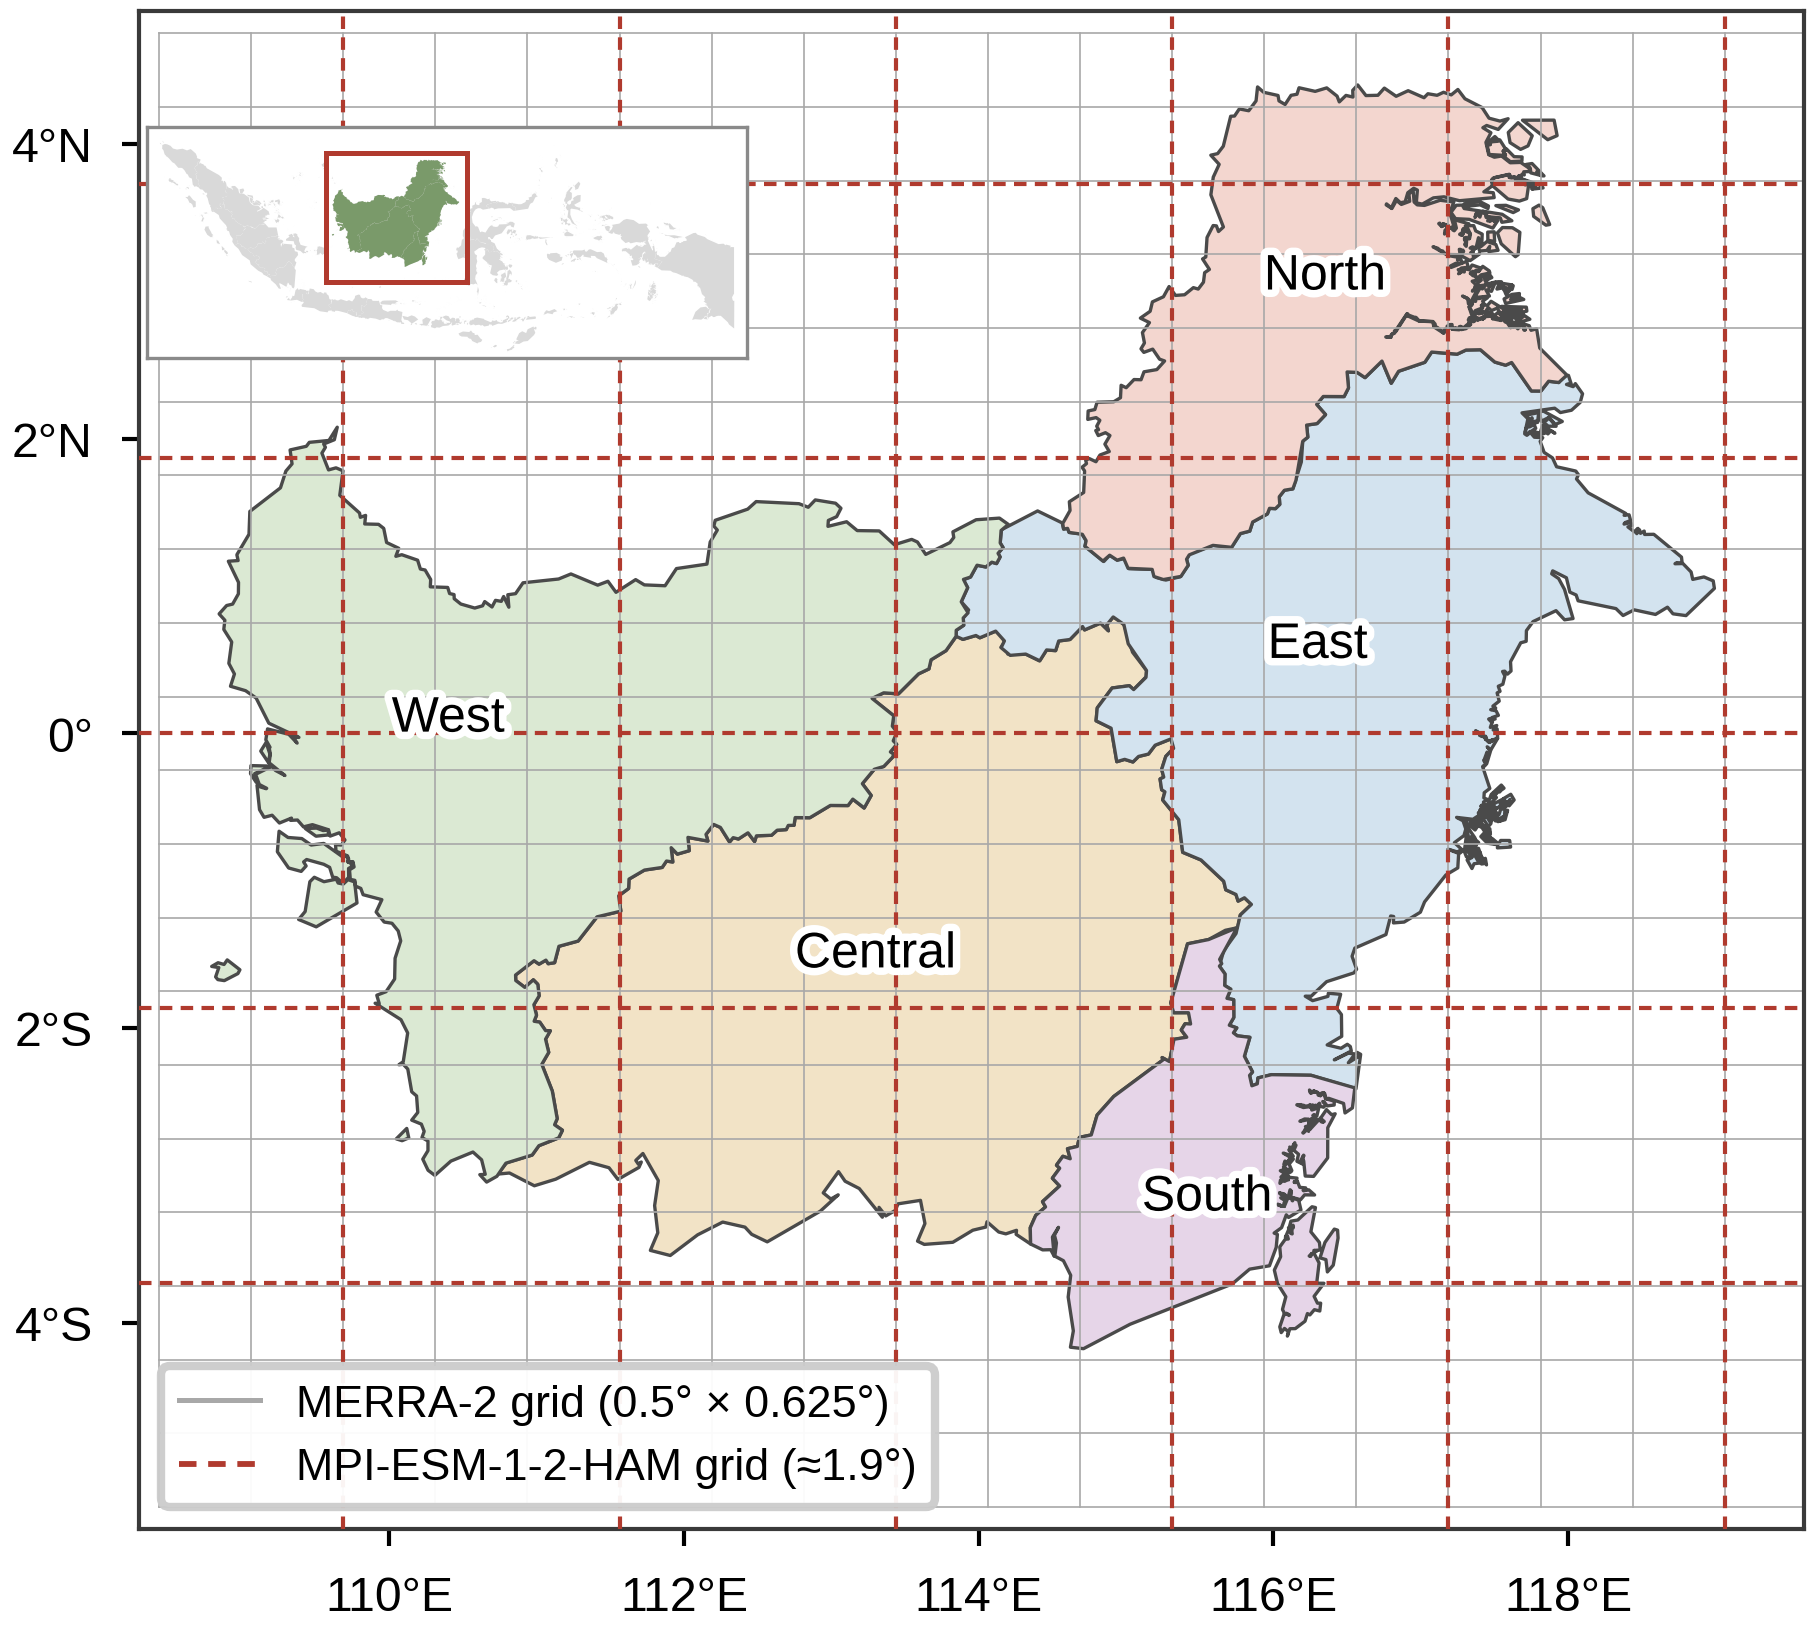

In [ ]:
gadm = gpd.read_file(F_GADM if os.path.exists(F_GADM) else F_GADM_SHP)
gadm['NAME_1'] = gadm.NAME_1.str.replace(' ', '')
kal = gadm[gadm.NAME_1.isin(GADM_NAME)].copy()
kal['province'] = kal.NAME_1.map(GADM_NAME)
parts = kal.explode(index_parts=False)
parts = parts[parts.geometry.area > 0.003]
kal = parts.dissolve(by='province', as_index=False)
kal['geometry'] = kal.geometry.simplify(0.015)

idn = gadm.copy()
idn['geometry'] = idn.geometry.simplify(0.05)
fill = {'West Kalimantan': '#dbe9d3', 'Central Kalimantan': '#f2e3c6', 'South Kalimantan': '#e6d5e8',
        'East Kalimantan': '#d3e3ef', 'North Kalimantan': '#f3d6cf'}
x, _ = np.polynomial.legendre.leggauss(96)
mlat = np.sort(np.degrees(np.arcsin(x)))
mlon = np.arange(192) * 1.875
fig, ax = plt.subplots(figsize=(W, 2.95))
for _, r in kal.iterrows():
    gpd.GeoSeries([r.geometry]).plot(ax=ax, color=fill[r.province], edgecolor='#4a4a4a', lw=0.4)
LAT = np.arange(-5.0, 4.5 + 1e-9, 0.5)
LON = 108.75 + 0.625 * np.arange(18)
for la in np.r_[LAT - 0.25, LAT[-1] + 0.25]:
    ax.plot([LON[0] - 0.3125, LON[-1] + 0.3125], [la, la], color='#a8a8a8', lw=0.2, zorder=2)
for lo in np.r_[LON - 0.3125, LON[-1] + 0.3125]:
    ax.plot([lo, lo], [LAT[0] - 0.25, LAT[-1] + 0.25], color='#a8a8a8', lw=0.2, zorder=2)
latb = (mlat[:-1] + mlat[1:]) / 2
lonb = (mlon[:-1] + mlon[1:]) / 2
for la in latb[(latb > -6) & (latb < 6)]:
    ax.plot([108.3, 119.6], [la, la], color='#b03a2e', lw=0.5, ls=(0, (3, 2)), zorder=3)
for lo in lonb[(lonb > 108) & (lonb < 120)]:
    ax.plot([lo, lo], [-5.4, 4.9], color='#b03a2e', lw=0.5, ls=(0, (3, 2)), zorder=3)
label_xy = {'West Kalimantan': (110.4, 0.1), 'Central Kalimantan': (113.3, -1.5), 'South Kalimantan': (115.55, -3.15),
            'East Kalimantan': (116.3, 0.6), 'North Kalimantan': (116.35, 3.1)}
for p, (x0, y0) in label_xy.items():
    ax.text(x0, y0, SHORT[p], ha='center', va='center', fontsize=6,
            path_effects=[pe.withStroke(linewidth=1.8, foreground='white')], zorder=5)
ax.set_xlim(108.3, 119.6); ax.set_ylim(-5.4, 4.9); ax.set_aspect('equal'); ax.set_xlabel(''); ax.set_ylabel('')
ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(2))
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:.0f}°E'))
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{abs(v):.0f}°{"S" if v < 0 else "N" if v > 0 else ""}'))
for s in ['top', 'right']:
    ax.spines[s].set_visible(True)
ax.legend([plt.Line2D([], [], color='#a8a8a8', lw=0.6), plt.Line2D([], [], color='#b03a2e', lw=0.7, ls=(0, (3, 2)))],
          ['MERRA-2 grid (0.5° × 0.625°)', 'MPI-ESM-1-2-HAM grid (≈1.9°)'],
          loc='lower left', frameon=True, framealpha=0.95, edgecolor='#cccccc', fontsize=5.4, handlelength=1.8)
ia = ax.inset_axes([0.005, 0.70, 0.36, 0.295])
idn.plot(ax=ia, color='#d9d9d9', edgecolor='none')
kal.plot(ax=ia, color='#7a9a6a', edgecolor='none')
ia.add_patch(matplotlib.patches.Rectangle((108.3, -5.4), 11.3, 10.3, fill=False, edgecolor='#b03a2e', lw=0.6))
ia.set_xlim(94, 142); ia.set_ylim(-11.5, 7); ia.set_xticks([]); ia.set_yticks([]); ia.set_aspect('equal')
ia.set_xlabel(''); ia.set_ylabel('')
for s in ia.spines.values():
    s.set_edgecolor('#8a8a8a'); s.set_linewidth(0.4); s.set_visible(True)
save_figure(fig, 'Figure1')

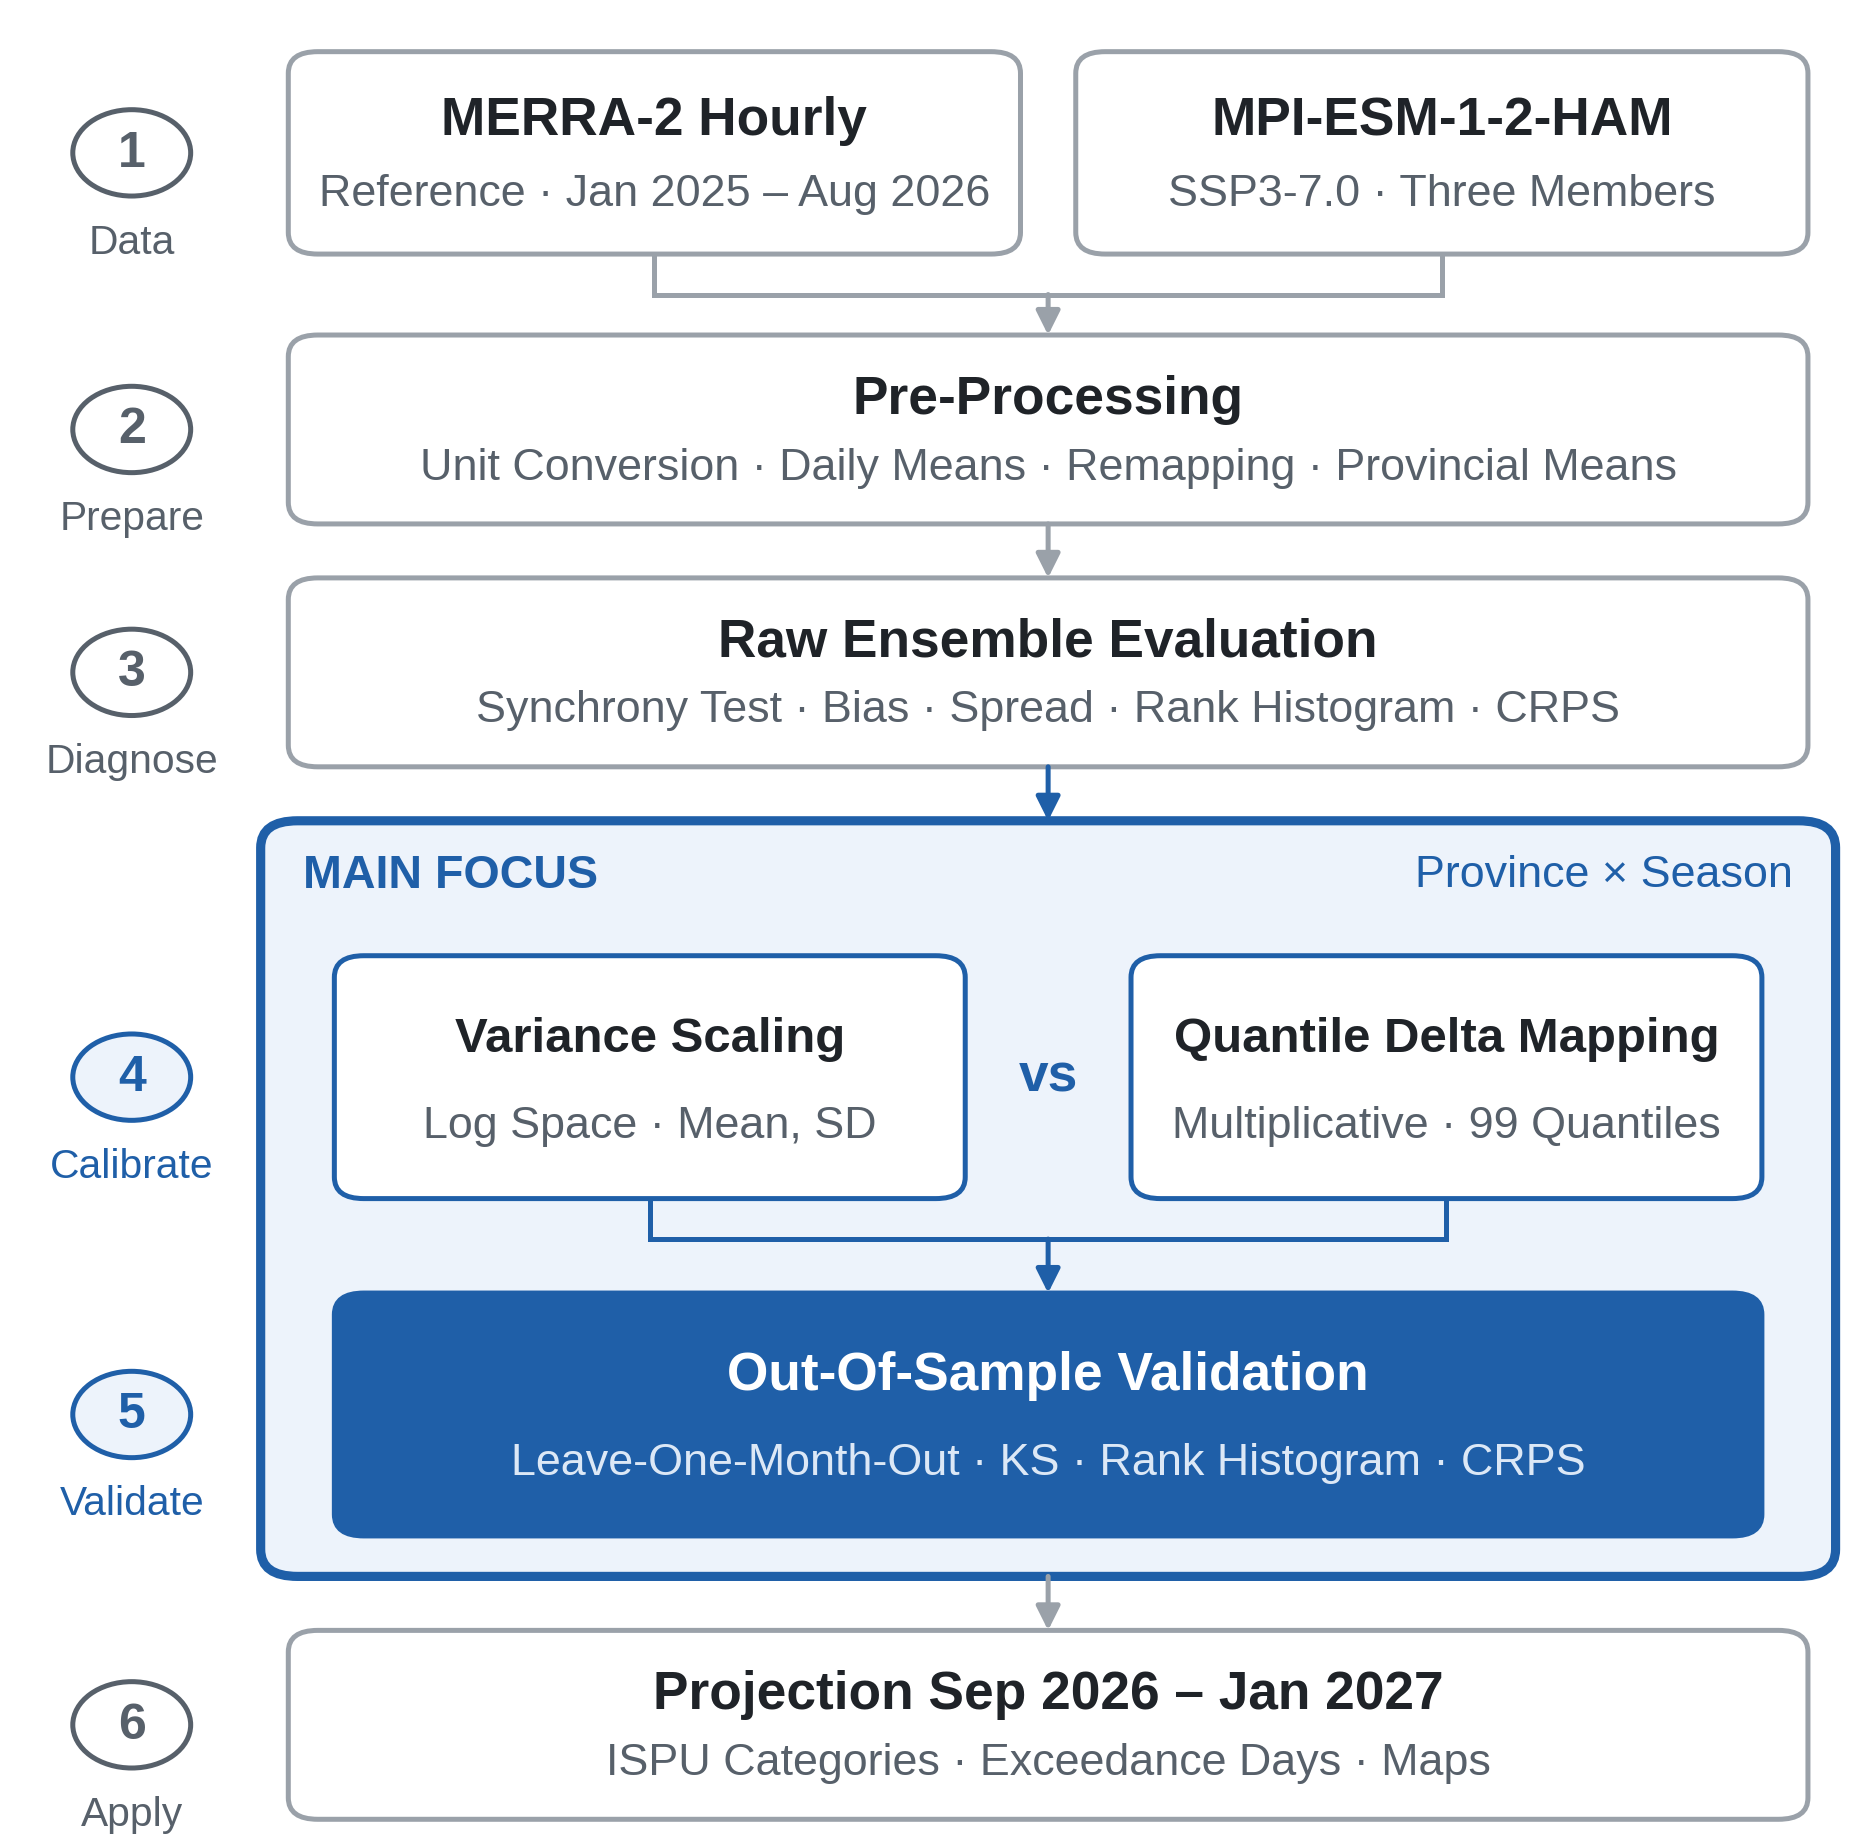

In [ ]:
INK, Q, EDGE, ACC, ACCF = '#1f2328', '#57606a', '#9aa1a9', '#1f5fa8', '#edf3fb'
fig = plt.figure(figsize=(W, 3.45 * H))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 100); ax.set_ylim(0, 135); ax.axis('off')
X0, X1 = 15, 97.5
MID = (X0 + X1) / 2


def box(x, y, w, h, title, sub, fc='white', ec=EDGE, tc=INK, lc=Q, lw=0.6, tfs=6.4):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0,rounding_size=1.6', fc=fc, ec=ec, lw=lw))
    ax.text(x + w / 2, y + h * 0.66, title, ha='center', va='center', fontsize=tfs, weight='bold', color=tc)
    ax.text(x + w / 2, y + h * 0.30, sub, ha='center', va='center', fontsize=5.4, color=lc)


def arrow(x1, y1, x2, y2, c=EDGE):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='-|>', color=c, lw=0.6, mutation_scale=6, shrinkA=0, shrinkB=0))


def step(y, n, text, c=Q, fc='white'):
    ax.add_patch(Circle((6.5, y), 3.2, fc=fc, ec=c, lw=0.6))
    ax.text(6.5, y, str(n), ha='center', va='center', fontsize=6, weight='bold', color=c)
    ax.text(6.5, y - 5.2, text, ha='center', va='top', fontsize=4.9, color=c)


gw = (X1 - X0 - 3) / 2
box(X0, 117, gw, 15, 'MERRA-2 Hourly', 'Reference · Jan 2025 – Aug 2026')
box(X0 + gw + 3, 117, gw, 15, 'MPI-ESM-1-2-HAM', 'SSP3-7.0 · Three Members')
step(124.5, 1, 'Data')
for xc in (X0 + gw / 2, X0 + gw + 3 + gw / 2):
    ax.plot([xc, xc], [117, 114], color=EDGE, lw=0.6)
ax.plot([X0 + gw / 2, X0 + gw + 3 + gw / 2], [114, 114], color=EDGE, lw=0.6)
arrow(MID, 114, MID, 111)
box(X0, 97, X1 - X0, 14, 'Pre-Processing', 'Unit Conversion · Daily Means · Remapping · Provincial Means')
step(104, 2, 'Prepare')
arrow(MID, 97, MID, 93)
box(X0, 79, X1 - X0, 14, 'Raw Ensemble Evaluation', 'Synchrony Test · Bias · Spread · Rank Histogram · CRPS')
step(86, 3, 'Diagnose')
ax.add_patch(FancyBboxPatch((X0 - 1.5, 19), X1 - X0 + 3, 56, boxstyle='round,pad=0,rounding_size=2', fc=ACCF, ec=ACC, lw=1.1))
ax.text(X0 + 0.8, 71, 'MAIN FOCUS', fontsize=5.6, weight='bold', color=ACC, va='center')
ax.text(X1 - 0.8, 71, 'Province × Season', fontsize=5.4, color=ACC, va='center', ha='right')
arrow(MID, 79, MID, 75, c=ACC)
cw = (X1 - X0 - 14) / 2
box(X0 + 2.5, 47, cw, 18, 'Variance Scaling', 'Log Space · Mean, SD', ec=ACC, tfs=5.9)
ax.text(MID, 56, 'vs', ha='center', va='center', fontsize=6.4, weight='bold', color=ACC)
box(X1 - 2.5 - cw, 47, cw, 18, 'Quantile Delta Mapping', 'Multiplicative · 99 Quantiles', ec=ACC, tfs=5.9)
for xc in (X0 + 2.5 + cw / 2, X1 - 2.5 - cw / 2):
    ax.plot([xc, xc], [47, 44], color=ACC, lw=0.6)
ax.plot([X0 + 2.5 + cw / 2, X1 - 2.5 - cw / 2], [44, 44], color=ACC, lw=0.6)
arrow(MID, 44, MID, 40, c=ACC)
box(X0 + 2.5, 22, X1 - X0 - 5, 18, 'Out-Of-Sample Validation', 'Leave-One-Month-Out · KS · Rank Histogram · CRPS',
    fc=ACC, ec=ACC, tc='white', lc='#dce8f6')
step(56, 4, 'Calibrate', c=ACC, fc=ACCF)
step(31, 5, 'Validate', c=ACC, fc=ACCF)
arrow(MID, 19, MID, 15)
box(X0, 1, X1 - X0, 14, 'Projection Sep 2026 – Jan 2027', 'ISPU Categories · Exceedance Days · Maps')
step(8, 6, 'Apply')
save_figure(fig, 'Figure2')

## 4. Descriptive Statistics

In [ ]:
def summarise(x):
    x = np.asarray(x)
    return pd.Series({'mean': x.mean(), 'median': np.median(x), 'sd': x.std(ddof=1),
                      'min': x.min(), 'max': x.max(), 'p90': np.quantile(x, .90),
                      'p95': np.quantile(x, .95), 'p99': np.quantile(x, .99),
                      'skewness': stats.skew(x), 'days_above_55': int((x > STANDARD_24H).sum())})


rows = []
for p in PROV:
    for s in ['Dry', 'Wet', 'All']:
        d = cal[(cal.province == p) & ((cal.season == s) | (s == 'All'))]
        for source, x in [('MERRA-2', d.merra2.values), (MODEL, d[MEMBERS].values.ravel())]:
            r = summarise(x)
            r['province'], r['season'], r['source'] = p, s, source
            rows.append(r)
descriptive = pd.DataFrame(rows).set_index(['province', 'season', 'source'])
save_table(descriptive.round(3), 'descriptive_statistics')

by_year = cal.assign(year=cal.date.dt.year)
full_years = [y for y, d in by_year.groupby('year') if d.date.dt.month.nunique() == 12]
annual = (by_year[by_year.year.isin(full_years)].assign(model=by_year[MEMBERS].mean(axis=1))
          .groupby(['province', 'year'])[['merra2', 'model']].mean().unstack('year').loc[PROV])
save_table(annual.round(2), 'annual_means')

member_means = cal.groupby('province')[MEMBERS].mean().loc[PROV]
save_table(member_means.round(2), 'member_means')
print('Annual mean PM2.5 (µg m-3):')
print(annual.round(2).to_string())
print('\nMean PM2.5 per member (µg m-3):')
print(member_means.round(2).to_string())
descriptive.xs('All', level='season').round(2)

Annual mean PM2.5 (µg m-3):
                   merra2 model
year                 2025  2025
province                       
West Kalimantan      7.35  6.46
Central Kalimantan   6.67  8.08
South Kalimantan     7.54  8.25
East Kalimantan      5.49  4.33
North Kalimantan     3.81  3.89

Mean PM2.5 per member (µg m-3):
                      r1    r2     r3
province                             
West Kalimantan     5.13  5.04   9.51
Central Kalimantan  5.79  5.92  10.36
South Kalimantan    6.50  6.86   8.31
East Kalimantan     3.29  3.26   6.07
North Kalimantan    2.51  2.59   6.77


mean  median     sd   min     max    p90  \
province           source                                                      
West Kalimantan    MERRA-2          9.62    7.01  11.97  1.98  145.33  14.82   
                   MPI-ESM-1-2-HAM  6.56    5.69   3.77  1.19   35.05  10.38   
Central Kalimantan MERRA-2          8.45    6.61   9.81  1.46  159.89  12.61   
                   MPI-ESM-1-2-HAM  7.36    5.30   5.74  1.26   58.57  14.28   
South Kalimantan   MERRA-2          8.24    7.47   3.91  2.28   22.20  13.03   
                   MPI-ESM-1-2-HAM  7.22    5.13   6.51  1.11   54.45  13.19   
East Kalimantan    MERRA-2          6.89    5.32   8.11  1.30  152.06  10.85   
                   MPI-ESM-1-2-HAM  4.21    3.56   2.22  1.22   28.42   6.56   
North Kalimantan   MERRA-2          4.99    3.79   6.61  1.03   98.22   7.18   
                   MPI-ESM-1-2-HAM  3.96    2.72   3.70  0.98   37.04   7.26   

                                      p95    p99  skewness  days_above_55  
province           source                                                  
West Kalimantan    MERRA-2          19.24  63.83      6.44            9.0  
                   MPI-ESM-1-2-HAM  13.49  21.95      2.70            0.0  
Central Kalimantan MERRA-2          15.68  54.91      8.42            7.0  
                   MPI-ESM-1-2-HAM  21.06  28.14      2.53            1.0  
South Kalimantan   MERRA-2          15.62  21.00      1.12            0.0  
                   MPI-ESM-1-2-HAM  21.29  34.86      2.97            0.0  
East Kalimantan    MERRA-2          14.71  35.56     10.99            2.0  
                   MPI-ESM-1-2-HAM   8.30  12.42      3.23            0.0  
North Kalimantan   MERRA-2          11.05  27.55      9.01            3.0  
                   MPI-ESM-1-2-HAM  10.87  20.40      4.18            0.0

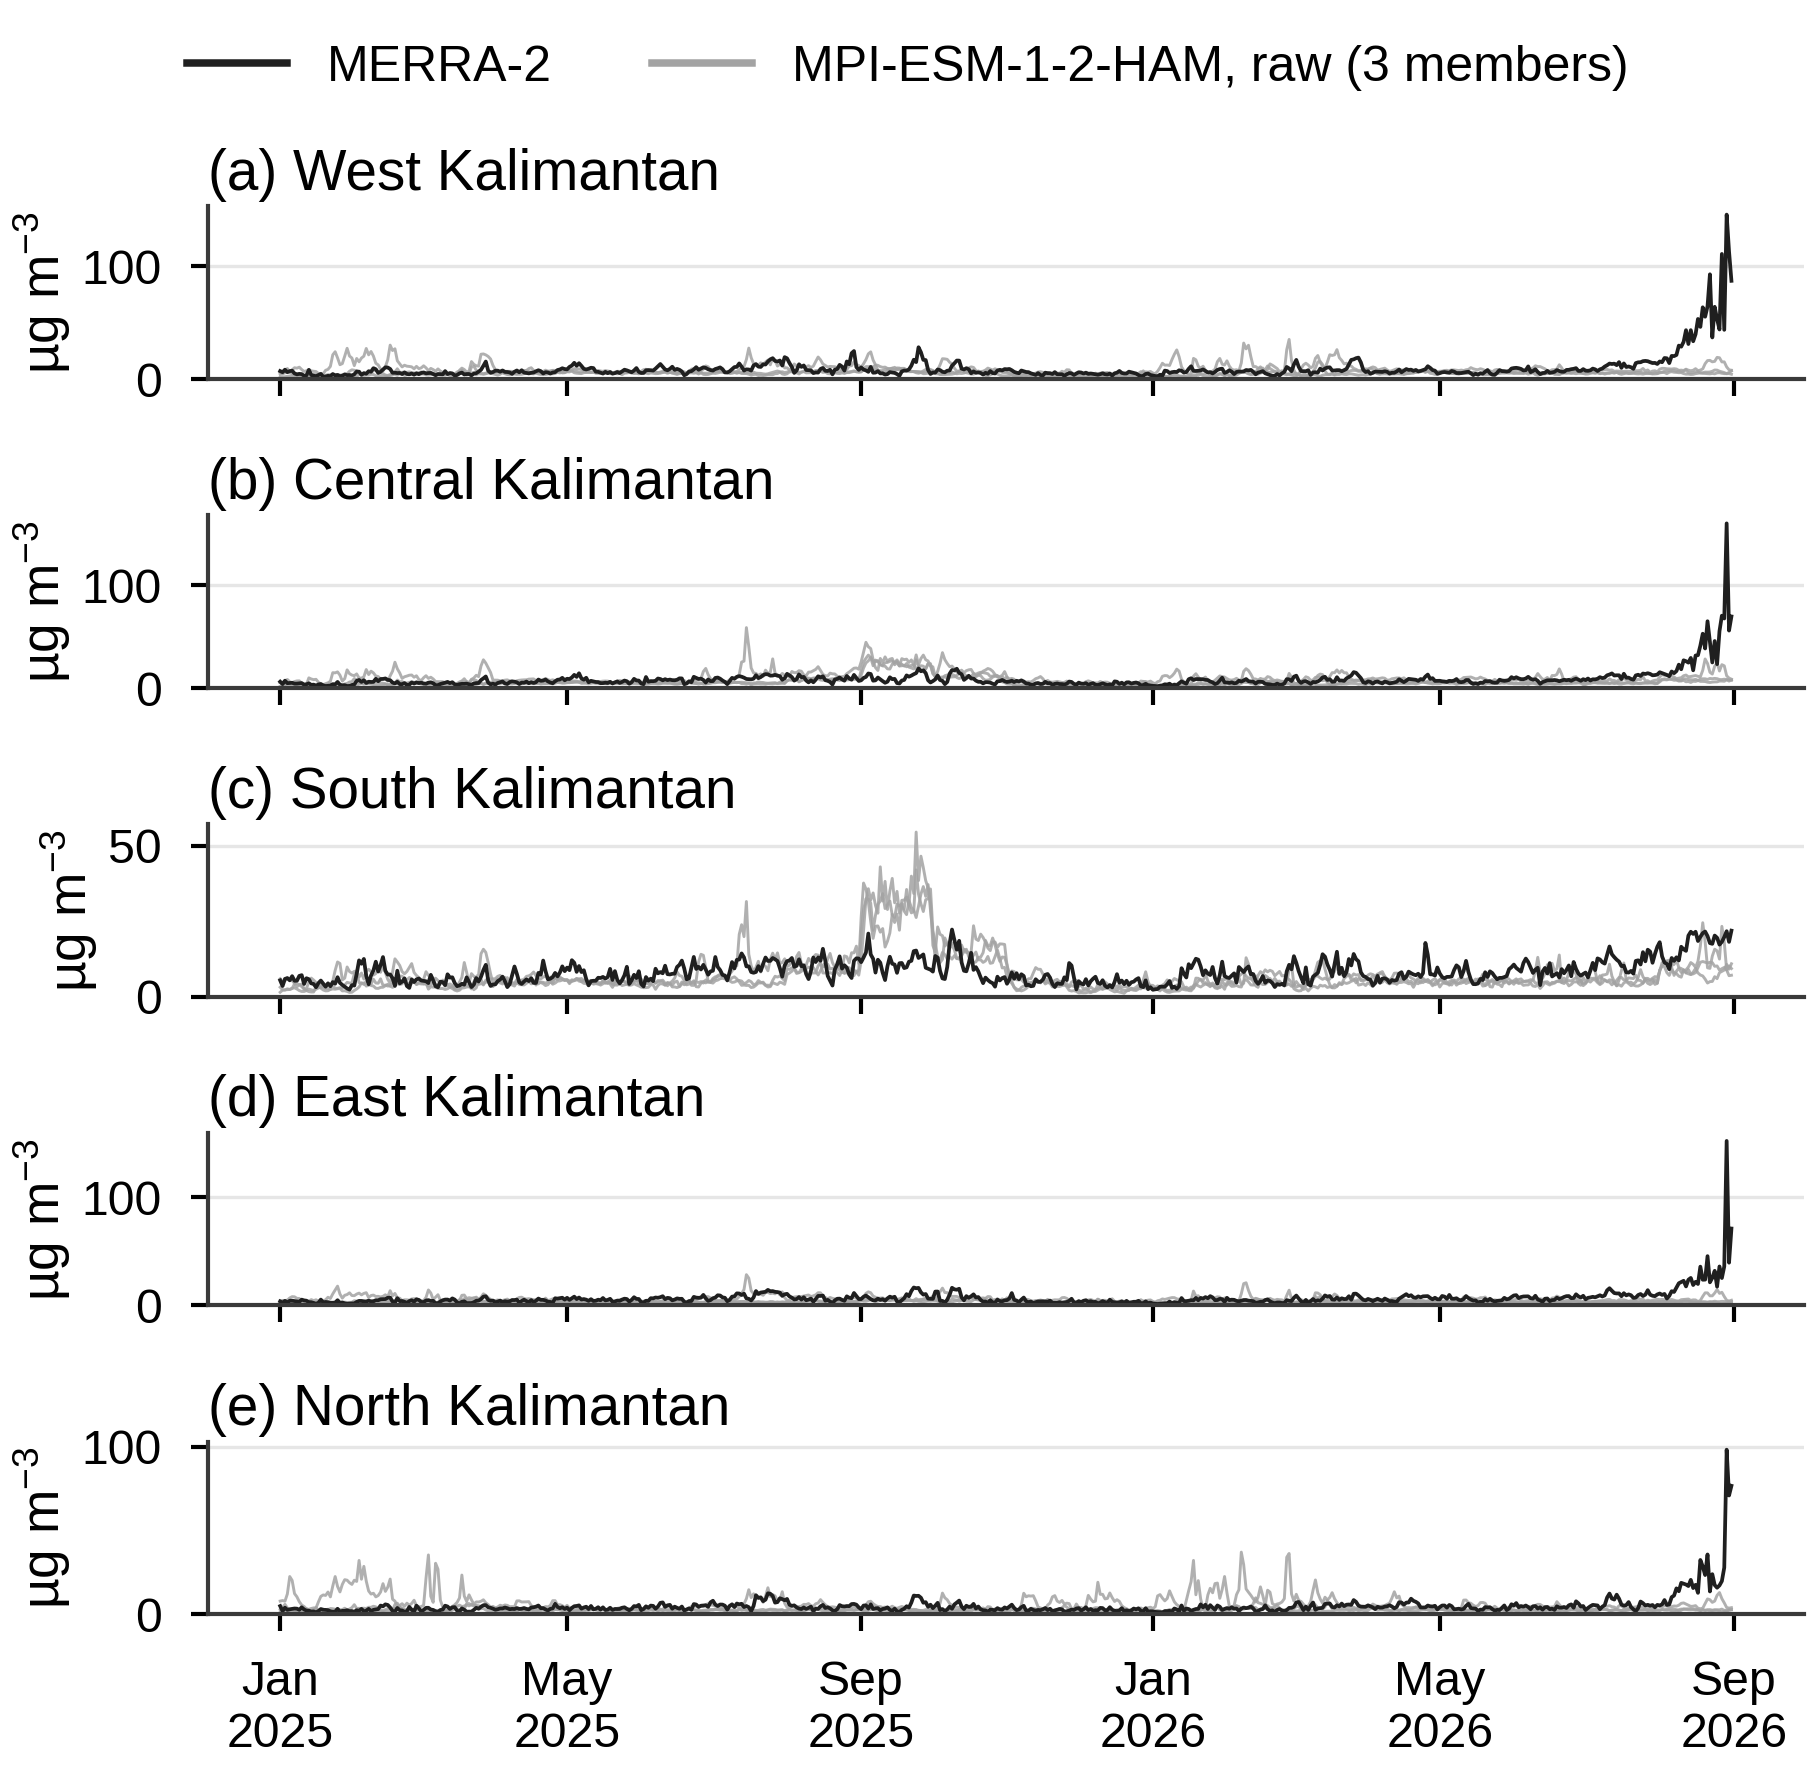

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(W, 3.4 * H), sharex=True)
for ax, p, letter in zip(axes, PROV, 'abcde'):
    d = cal[cal.province == p]
    for m in MEMBERS:
        ax.plot(d.date, d[m], color=COLOR['Raw'], lw=0.35, alpha=0.85)
    ax.plot(d.date, d.merra2, color=COLOR['MERRA-2'], lw=0.45)
    panel_title(ax, letter, p); grid(ax); ax.set_ylim(bottom=0); ax.set_ylabel('µg m$^{-3}$', labelpad=1)
date_axis(axes[-1])
fig.legend([plt.Line2D([], [], color=COLOR['MERRA-2'], lw=0.9), plt.Line2D([], [], color=COLOR['Raw'], lw=0.9)],
           ['MERRA-2', 'MPI-ESM-1-2-HAM, raw (3 members)'], loc='outside upper center', ncol=2)
save_figure(fig, 'Figure3')

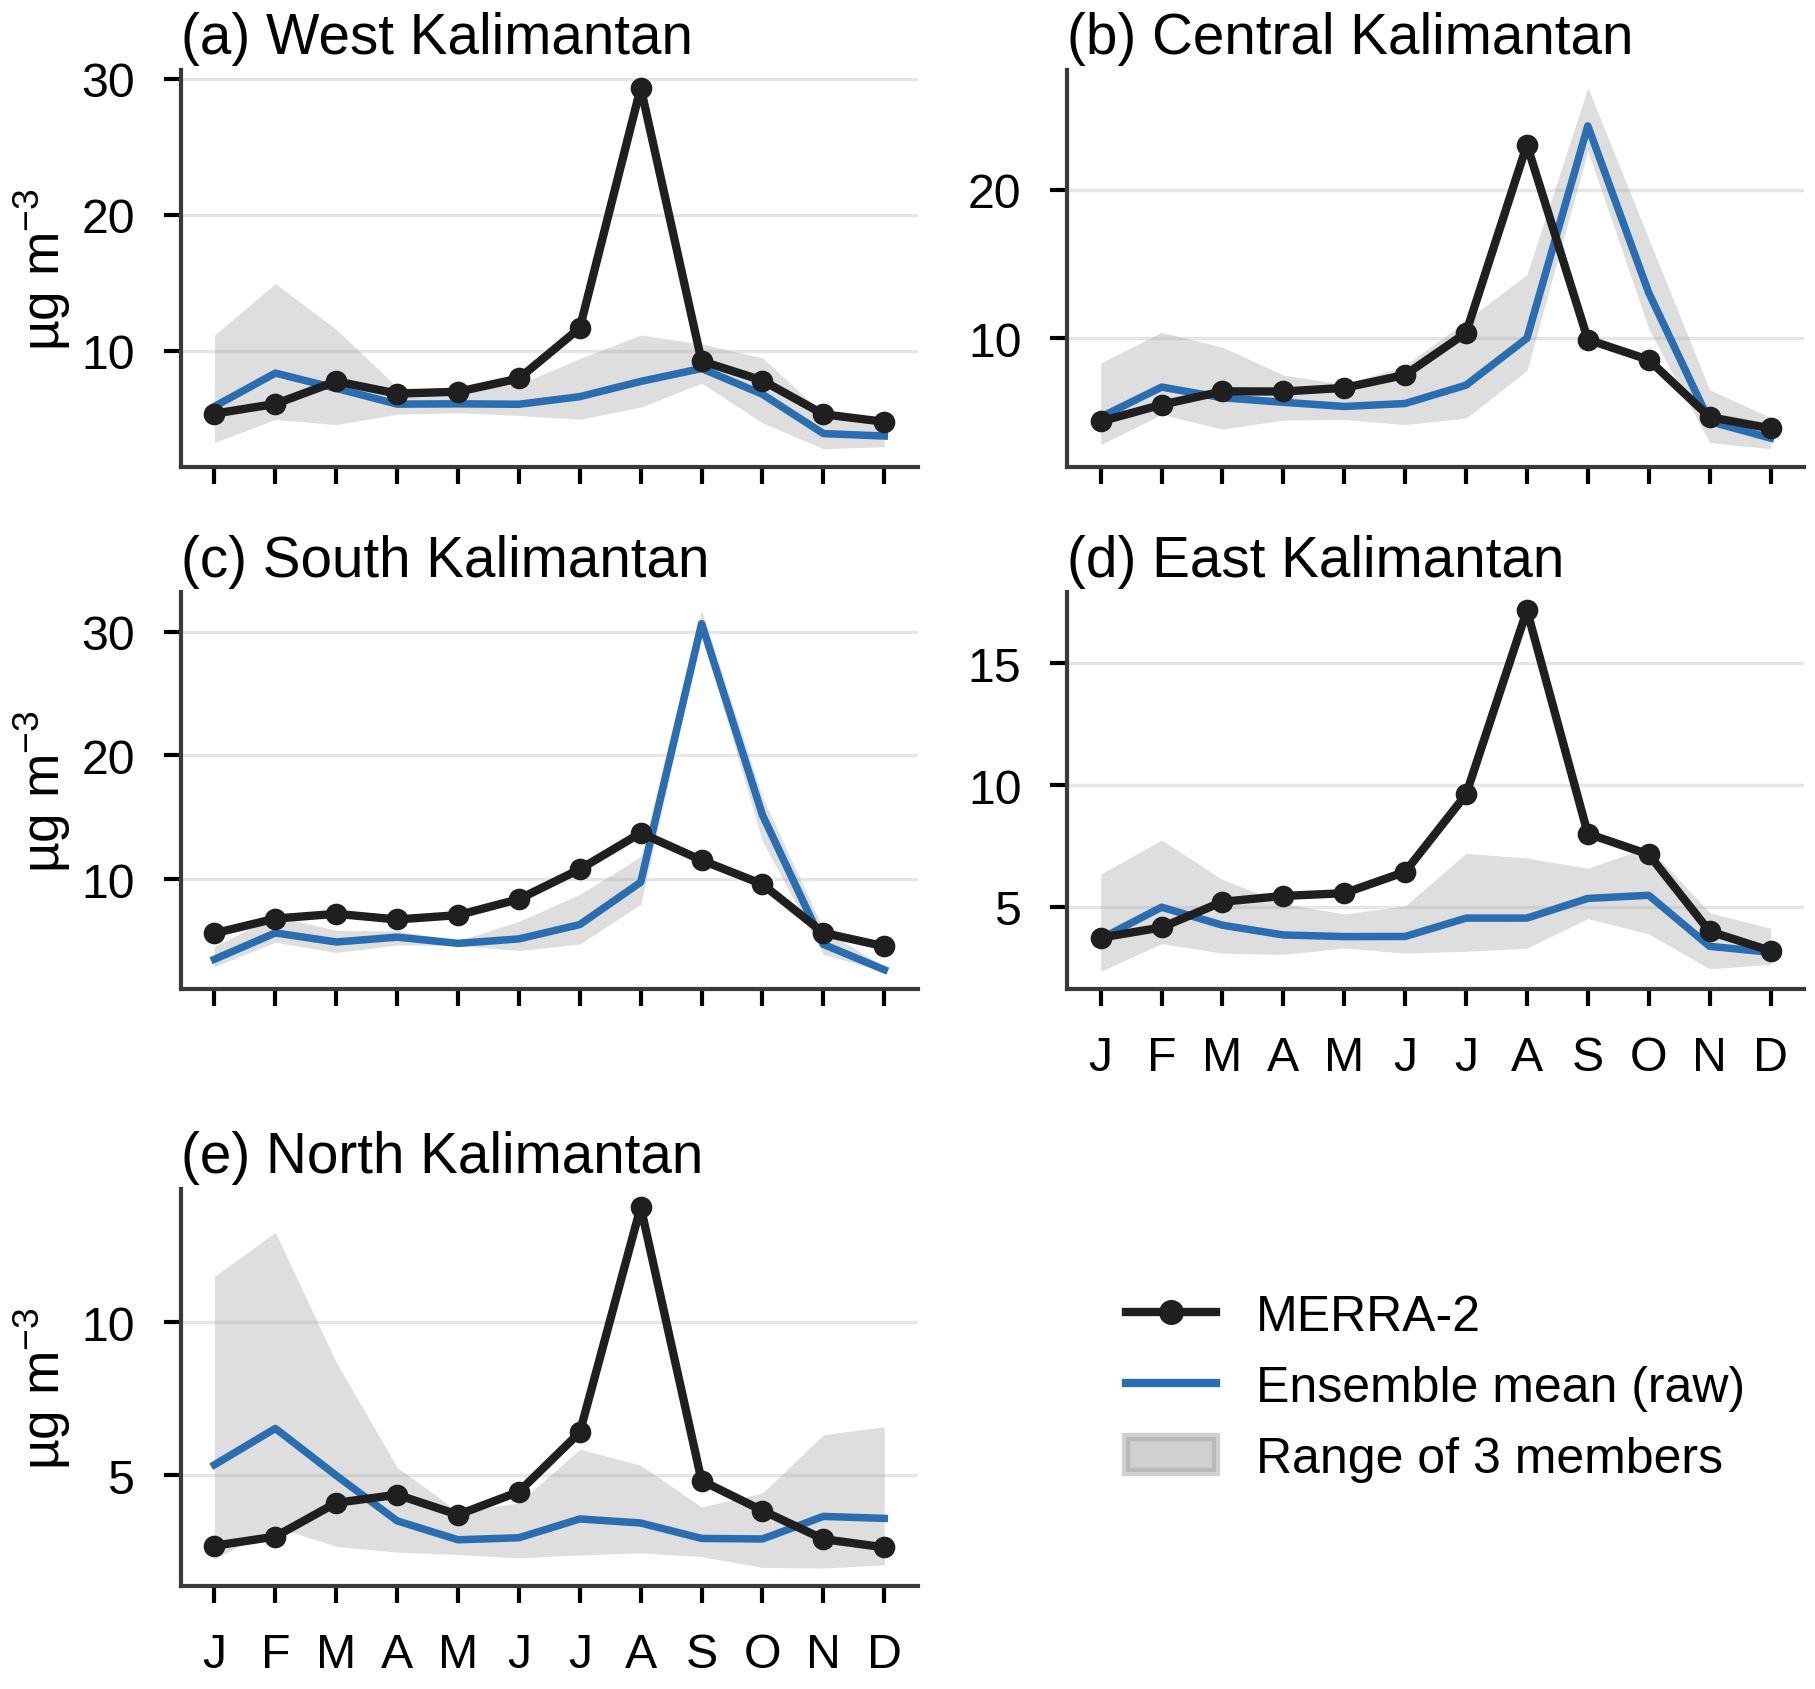

In [ ]:
clim = cal.assign(m=cal.date.dt.month).groupby(['province', 'm'])[['merra2'] + MEMBERS].mean()
fig, axes = plt.subplots(3, 2, figsize=(W, 3.25 * H), sharex=True)
for ax, p, letter in zip(axes.flat, PROV, 'abcde'):
    t = clim.loc[p]
    ax.fill_between(t.index, t[MEMBERS].min(axis=1), t[MEMBERS].max(axis=1), color=COLOR['Raw'], alpha=0.35, lw=0)
    ax.plot(t.index, t[MEMBERS].mean(axis=1), color=COLOR['QDM'], lw=0.9)
    ax.plot(t.index, t.merra2, color=COLOR['MERRA-2'], lw=1.0, marker='o', ms=1.6)
    panel_title(ax, letter, p); grid(ax); ax.set_xticks(range(1, 13)); ax.set_xticklabels([m[0] for m in MONTHS])
for ax in axes[:, 0]:
    ax.set_ylabel('µg m$^{-3}$', labelpad=1)
axes.flat[4].tick_params(labelbottom=True); axes.flat[3].tick_params(labelbottom=True); axes.flat[5].axis('off')
axes.flat[5].legend([plt.Line2D([], [], color=COLOR['MERRA-2'], lw=1, marker='o', ms=2),
                     plt.Line2D([], [], color=COLOR['QDM'], lw=1), matplotlib.patches.Patch(color=COLOR['Raw'], alpha=0.5)],
                    ['MERRA-2', 'Ensemble mean (raw)', 'Range of 3 members'], loc='center', handlelength=1.8)
save_figure(fig, 'Figure4')

## 5. Evaluation of the Raw Ensemble

In [ ]:
def distribution_scores(x, y):
    x, y = np.asarray(x).ravel(), np.asarray(y).ravel()
    return {'bias': x.mean() - y.mean(), 'rel_bias_pct': (x.mean() - y.mean()) / y.mean() * 100,
            'sd_ratio': x.std(ddof=1) / y.std(ddof=1),
            'dP10': np.quantile(x, .1) - np.quantile(y, .1), 'dP50': np.median(x) - np.median(y),
            'dP90': np.quantile(x, .9) - np.quantile(y, .9), 'dP95': np.quantile(x, .95) - np.quantile(y, .95),
            'ks_d': stats.ks_2samp(x, y).statistic}


def rank_histogram(E, y):
    return np.bincount((E < y[:, None]).sum(1), minlength=E.shape[1] + 1)


def jolliffe_primo(n):
    n = np.asarray(n, float); e = n.sum() / len(n)
    k = np.arange(len(n)); lin = k - k.mean(); lin /= np.sqrt((lin ** 2).sum())
    u = (k - k.mean()) ** 2; u -= u.mean(); u /= np.sqrt((u ** 2).sum())
    chi = ((n - e) ** 2 / e).sum(); c_lin = (lin @ (n - e)) ** 2 / e; c_u = (u @ (n - e)) ** 2 / e
    return {'chi2_total': chi, 'chi2_linear': c_lin, 'p_linear': stats.chi2.sf(c_lin, 1),
            'chi2_u': c_u, 'p_u': stats.chi2.sf(c_u, 1)}


def crps_fair(E, y):
    E = np.asarray(E, float); m = E.shape[1]
    t1 = np.abs(E - y[:, None]).mean(1)
    t2 = np.abs(E[:, :, None] - E[:, None, :]).sum((1, 2)) / (2 * m * (m - 1))
    return t1 - t2


def brier(E, y, threshold):
    f = (E > threshold).mean(1); o = (y > threshold).astype(float); n = len(o); ob = o.mean()
    rel = res = 0.0
    for fk in np.unique(f):
        m = f == fk; ok = o[m].mean()
        rel += m.sum() * (fk - ok) ** 2; res += m.sum() * (ok - ob) ** 2
    return {'bs': np.mean((f - o) ** 2), 'reliability': rel / n, 'resolution': res / n,
            'uncertainty': ob * (1 - ob), 'event_frequency': ob}


def evaluate(E, y):
    E, y = np.asarray(E, float), np.asarray(y, float)
    rh = rank_histogram(E, y)
    out = distribution_scores(E, y)
    out.update({f'rank_{i + 1}_pct': v for i, v in enumerate(rh / rh.sum() * 100)})
    out.update(jolliffe_primo(rh))
    out['coverage_pct'] = np.mean((y >= E.min(1)) & (y <= E.max(1))) * 100
    out['crps'] = crps_fair(E, y).mean()
    return out


P90 = cal.groupby('province').merra2.quantile(0.9).to_dict()
print('MERRA-2 90th percentile per province (µg m-3):', {p: round(P90[p], 2) for p in PROV})

MERRA-2 90th percentile per province (µg m-3): {'West Kalimantan': 14.82, 'Central Kalimantan': 12.61, 'South Kalimantan': 13.03, 'East Kalimantan': 10.85, 'North Kalimantan': 7.18}


In [ ]:
rows = []
for p in PROV:
    d = cal[cal.province == p]
    month = d.date.dt.month
    a_obs = d.merra2 - d.groupby(month).merra2.transform('mean')
    ens = d[MEMBERS].mean(axis=1)
    a_mod = ens - ens.groupby(month).transform('mean')
    r = np.corrcoef(a_obs, a_mod)[0, 1]
    rows.append({'province': p, 'raw_correlation': np.corrcoef(d.merra2, ens)[0, 1],
                 'anomaly_correlation': r, 'anomaly_r2_pct': r ** 2 * 100})
synchrony = save_table(pd.DataFrame(rows).set_index('province').round(3), 'synchrony_test')
synchrony

,raw_correlation,anomaly_correlation,anomaly_r2_pct
province,,,
West Kalimantan,0.137,-0.019,0.038
Central Kalimantan,0.197,0.014,0.020
South Kalimantan,0.376,0.092,0.848
East Kalimantan,0.062,-0.058,0.341
North Kalimantan,-0.090,-0.008,0.006


In [ ]:
rows = []
for p in PROV:
    for s in ['Dry', 'Wet', 'All']:
        d = cal[(cal.province == p) & ((cal.season == s) | (s == 'All'))]
        r = evaluate(d[MEMBERS].values, d.merra2.values)
        r.update(province=p, season=s)
        rows.append(r)
raw_eval = pd.DataFrame(rows).set_index(['province', 'season'])
save_table(raw_eval.round(3), 'raw_ensemble_evaluation')
raw_eval[['bias', 'rel_bias_pct', 'sd_ratio', 'dP90', 'ks_d', 'coverage_pct', 'crps',
          'rank_1_pct', 'rank_2_pct', 'rank_3_pct', 'rank_4_pct', 'chi2_linear', 'chi2_u']].round(2)

bias  rel_bias_pct  sd_ratio   dP90  ks_d  \
province           season                                              
West Kalimantan    Dry    -7.39        -51.17      0.17 -13.63  0.45   
                   Wet    -0.13         -2.12      1.64   0.95  0.18   
                   All    -3.06        -31.80      0.32  -4.44  0.22   
Central Kalimantan Dry    -2.32        -18.43      0.51   4.32  0.27   
                   Wet    -0.26         -4.54      1.34   0.48  0.15   
                   All    -1.09        -12.89      0.59   1.67  0.19   
South Kalimantan   Dry     0.12          1.12      2.15   9.26  0.30   
                   Wet    -1.79        -27.75      0.73  -3.15  0.35   
                   All    -1.02        -12.36      1.66   0.16  0.33   
East Kalimantan    Dry    -5.67        -55.35      0.20  -9.18  0.60   
                   Wet    -0.67        -14.47      1.08  -0.88  0.26   
                   All    -2.69        -38.96      0.27  -4.28  0.36   
North Kalimantan   Dry    -4.05        -55.65      0.18  -7.43  0.53   
                   Wet     1.01         29.36      3.18   3.82  0.13   
                   All    -1.03        -20.60      0.56   0.09  0.28   

                           coverage_pct  crps  rank_1_pct  rank_2_pct  \
province           season                                               
West Kalimantan    Dry            30.61  7.44       11.84        6.94   
                   Wet            62.81  1.18       10.74       20.39   
                   All            49.84  3.70       11.18       14.97   
Central Kalimantan Dry            30.61  6.44       26.94        5.31   
                   Wet            62.81  1.05       11.57       20.11   
                   All            49.84  3.22       17.76       14.14   
South Kalimantan   Dry            23.27  5.11       24.90        3.67   
                   Wet            37.74  1.77        6.34       16.25   
                   All            31.91  3.12       13.82       11.18   
East Kalimantan    Dry            25.71  5.29        6.12        4.90   
                   Wet            50.41  1.12       12.40       15.98   
                   All            40.46  2.80        9.87       11.51   
North Kalimantan   Dry            34.69  3.70        4.90        2.86   
                   Wet            63.36  0.71       16.80       21.21   
                   All            51.81  1.92       12.01       13.82   

                           rank_3_pct  rank_4_pct  chi2_linear  chi2_u  
province           season                                               
West Kalimantan    Dry          23.67       57.55       116.02   36.84  
                   Wet          42.42       26.45        34.71   23.83  
                   All          34.87       38.98       129.73    0.01  
Central Kalimantan Dry          25.31       42.45        21.69   36.84  
                   Wet          42.70       25.62        30.43   23.83  
                   All          35.69       32.40        52.11    0.01  
South Kalimantan   Dry          19.59       51.84        45.85   70.04  
                   Wet          21.49       55.92       172.17   21.82  
                   All          20.72       54.28       208.43   79.61  
East Kalimantan    Dry          20.82       68.16       200.02   57.80  
                   Wet          34.44       37.19        62.57    0.02  
                   All          28.95       49.67       227.71   22.13  
North Kalimantan   Dry          31.84       60.41       187.30   22.96  
                   Wet          42.15       19.83         6.55   25.92  
                   All          37.99       36.18       113.73    0.80

## 6. Calibration Methods

In [ ]:
def fit_vs(model_train, obs_train):
    lm, lo = np.log(np.ravel(model_train)), np.log(np.ravel(obs_train))
    return {'mu_m': lm.mean(), 'sd_m': lm.std(ddof=1), 'mu_o': lo.mean(), 'sd_o': lo.std(ddof=1)}


def apply_vs(X, par):
    return np.exp((np.log(X) - par['mu_m']) * par['sd_o'] / par['sd_m'] + par['mu_o'])


def apply_qdm(X, model_train, obs_train):
    tau = stats.rankdata(X.ravel()) / (X.size + 1)
    tau = np.clip(tau, 0.01, 0.99)
    fm = np.quantile(np.ravel(model_train), tau)
    fo = np.quantile(np.ravel(obs_train), tau)
    return (fo * X.ravel() / fm).reshape(X.shape)


def calibrate(train, test):
    out_vs = np.full((len(test), M), np.nan); out_qdm = out_vs.copy()
    for (p, s), idx in test.groupby(['province', 'season']).groups.items():
        tr = train[(train.province == p) & (train.season == s)]
        par = fit_vs(tr[MEMBERS].values, tr.merra2.values)
        out_vs[test.index.get_indexer(idx)] = apply_vs(test.loc[idx, MEMBERS].values, par)
        for _, idm in test.loc[idx].groupby('month').groups.items():
            out_qdm[test.index.get_indexer(idm)] = apply_qdm(test.loc[idm, MEMBERS].values,
                                                             tr[MEMBERS].values, tr.merra2.values)
    return out_vs, out_qdm


rows = []
for p in PROV:
    for s in ['Dry', 'Wet']:
        tr = cal[(cal.province == p) & (cal.season == s)]
        r = fit_vs(tr[MEMBERS].values, tr.merra2.values)
        r.update(province=p, season=s, n_days=len(tr))
        rows.append(r)
save_table(pd.DataFrame(rows).set_index(['province', 'season']).round(4), 'vs_parameters')

mu_m    sd_m    mu_o    sd_o  n_days
province           season                                        
West Kalimantan    Dry     1.8888  0.3405  2.3683  0.6600     245
                   Wet     1.6778  0.5210  1.7804  0.3719     363
Central Kalimantan Dry     2.1298  0.6079  2.3031  0.5735     245
                   Wet     1.5529  0.5028  1.6484  0.4120     363
South Kalimantan   Dry     2.1633  0.6559  2.3213  0.3744     245
                   Wet     1.4589  0.4087  1.7885  0.3891     363
East Kalimantan    Dry     1.4323  0.3877  2.1000  0.5931     245
                   Wet     1.2814  0.4101  1.4468  0.4203     363
North Kalimantan   Dry     1.0745  0.4020  1.6801  0.6606     245
                   Wet     1.2303  0.6436  1.1536  0.4131     363

## 7. Leave-One-Month-Out Validation

In [ ]:
oos_vs = np.full((len(cal), M), np.nan); oos_qdm = oos_vs.copy()
for b in CAL_MONTHS:
    test = cal[cal.month == b]; train = cal[cal.month != b]
    v, q = calibrate(train, test)
    oos_vs[test.index], oos_qdm[test.index] = v, q
assert not np.isnan(oos_vs).any() and not np.isnan(oos_qdm).any()
ENS = {'Raw': cal[MEMBERS].values, 'VS': oos_vs, 'QDM': oos_qdm}

rows = []
for p in PROV:
    for s in ['Dry', 'Wet', 'All']:
        m = ((cal.province == p) & ((cal.season == s) | (s == 'All'))).values
        y = cal.merra2.values[m]
        for name, E in ENS.items():
            r = evaluate(E[m], y)
            r.update(province=p, season=s, method=name)
            r.update({f'bs_p90_{k}': v for k, v in brier(E[m], y, P90[p]).items()})
            rows.append(r)
validation = pd.DataFrame(rows).set_index(['province', 'season', 'method'])
save_table(validation.round(4), 'validation_leave_one_month_out')
validation.xs('All', level='season')[['bias', 'sd_ratio', 'dP95', 'ks_d', 'coverage_pct', 'chi2_total', 'crps', 'bs_p90_bs']].round(3)

bias  sd_ratio    dP95   ks_d  coverage_pct  \
province           method                                                 
West Kalimantan    Raw    -3.060     0.315  -5.751  0.218        49.836   
                   VS     -0.054     0.972   5.000  0.053        52.632   
                   QDM    -0.185     0.874   2.238  0.038        51.151   
Central Kalimantan Raw    -1.089     0.585   5.379  0.186        49.836   
                   VS      0.481     0.952  13.372  0.109        47.204   
                   QDM     0.240     0.941  13.968  0.127        43.092   
South Kalimantan   Raw    -1.019     1.664   5.675  0.329        31.908   
                   VS      0.467     1.534   3.603  0.085        34.868   
                   QDM     1.072     2.185   7.791  0.130        31.579   
East Kalimantan    Raw    -2.685     0.274  -6.417  0.359        40.461   
                   VS      0.220     1.165   2.929  0.085        50.164   
                   QDM    -0.165     0.723   0.806  0.030        53.125   
North Kalimantan   Raw    -1.028     0.560  -0.176  0.285        51.809   
                   VS      0.108     1.105   0.721  0.094        53.454   
                   QDM    -0.058     0.811   0.502  0.069        52.961   

                           chi2_total   crps  bs_p90_bs  
province           method                                
West Kalimantan    Raw        142.118  3.700      0.102  
                   VS          22.855  3.453      0.128  
                   QDM         16.145  3.329      0.112  
Central Kalimantan Raw         82.513  3.219      0.125  
                   VS          37.355  4.132      0.148  
                   QDM         26.474  3.891      0.151  
South Kalimantan   Raw        289.737  3.115      0.133  
                   VS          65.842  2.697      0.140  
                   QDM         97.224  3.582      0.143  
East Kalimantan    Raw        251.737  2.800      0.096  
                   VS          33.697  2.218      0.118  
                   QDM         18.303  2.128      0.111  
North Kalimantan   Raw        142.961  1.916      0.116  
                   VS          53.855  1.592      0.100  
                   QDM          9.737  1.670      0.104

In [ ]:
rows = []
y = cal.merra2.values
for name, E in ENS.items():
    rows.append({'method': name,
                 'ks_d_mean_province': validation.xs('All', level='season').xs(name, level='method')['ks_d'].mean(),
                 'chi2_rank_histogram': jolliffe_primo(rank_histogram(E, y))['chi2_total'],
                 'bias': E.mean() - y.mean(), 'sd_ratio': E.std(ddof=1) / y.std(ddof=1),
                 'coverage_pct': np.mean((y >= E.min(1)) & (y <= E.max(1))) * 100,
                 'crps': crps_fair(E, y).mean()})
summary = pd.DataFrame(rows).set_index('method')
save_table(summary.round(4), 'validation_summary')

cand = summary.loc[['VS', 'QDM']]
score = cand['ks_d_mean_province'].rank() + cand['chi2_rank_histogram'].rank()
SELECTED = cand.loc[score[score == score.min()].index, 'ks_d_mean_province'].idxmin()

strata = validation.drop(index='All', level='season')
wins_ks = strata['ks_d'].unstack('method')[['VS', 'QDM']].idxmin(axis=1).value_counts().reindex(['VS', 'QDM'], fill_value=0)
wins_crps = strata['crps'].unstack('method')[['VS', 'QDM']].idxmin(axis=1).value_counts().reindex(['VS', 'QDM'], fill_value=0)
print('Rank score (KS D + chi2, lower is better):', score.to_dict())
print('Province-season strata with the lowest KS D:', wins_ks.to_dict())
print('Province-season strata with the lowest CRPS:', wins_crps.to_dict())
print('Selected method:', SELECTED)
summary.round(3)

Rank score (KS D + chi2, lower is better): {'VS': 4.0, 'QDM': 2.0}
Province-season strata with the lowest KS D: {'VS': 3, 'QDM': 7}
Province-season strata with the lowest CRPS: {'VS': 5, 'QDM': 5}
Selected method: QDM


,ks_d_mean_province,chi2_rank_histogram,bias,sd_ratio,coverage_pct,crps
method,,,,,,
Raw,0.275,766.434,-1.776,0.563,44.770,2.950
VS,0.085,146.618,0.244,1.049,47.664,2.818
QDM,0.079,74.387,0.181,0.959,46.382,2.920


In [ ]:
test_year = cal.date.dt.year.min() + 1
train = cal[cal.date.dt.year < test_year]; test = cal[cal.date.dt.year >= test_year].copy()
v, q = calibrate(train, test)
rows = []
for p in PROV:
    m = (test.province == p).values; y = test.merra2.values[m]
    for name, E in [('Raw', test[MEMBERS].values), ('VS', v), ('QDM', q)]:
        rows.append({'province': p, 'method': name, 'crps': crps_fair(E[m], y).mean(), 'bias': E[m].mean() - y.mean()})
time_split = pd.DataFrame(rows).set_index(['province', 'method'])
save_table(time_split.round(4), 'validation_time_split')
print(f'Train: {date_text(train.date.min())} – {date_text(train.date.max())} | '
      f'Test: {date_text(test.date.min())} – {date_text(test.date.max())}')
print(f'Mean MERRA-2: train {train.merra2.mean():.2f}, test {test.merra2.mean():.2f} µg m-3')
time_split.unstack('method').round(3)

Train: 1 January 2025 – 31 December 2025 | Test: 1 January 2026 – 31 August 2026
Mean MERRA-2: train 6.17, test 9.84 µg m-3


crps                 bias              
method                QDM    Raw     VS    QDM    Raw     VS
province                                                    
Central Kalimantan  5.562  4.782  5.139 -5.300 -4.843 -5.077
East Kalimantan     3.856  4.857  3.984 -4.039 -4.981 -4.105
North Kalimantan    2.980  3.353  2.953 -2.792 -2.688 -2.910
South Kalimantan    3.214  3.148  2.752 -2.951 -3.609 -2.543
West Kalimantan     5.980  6.717  6.008 -5.522 -6.328 -5.858

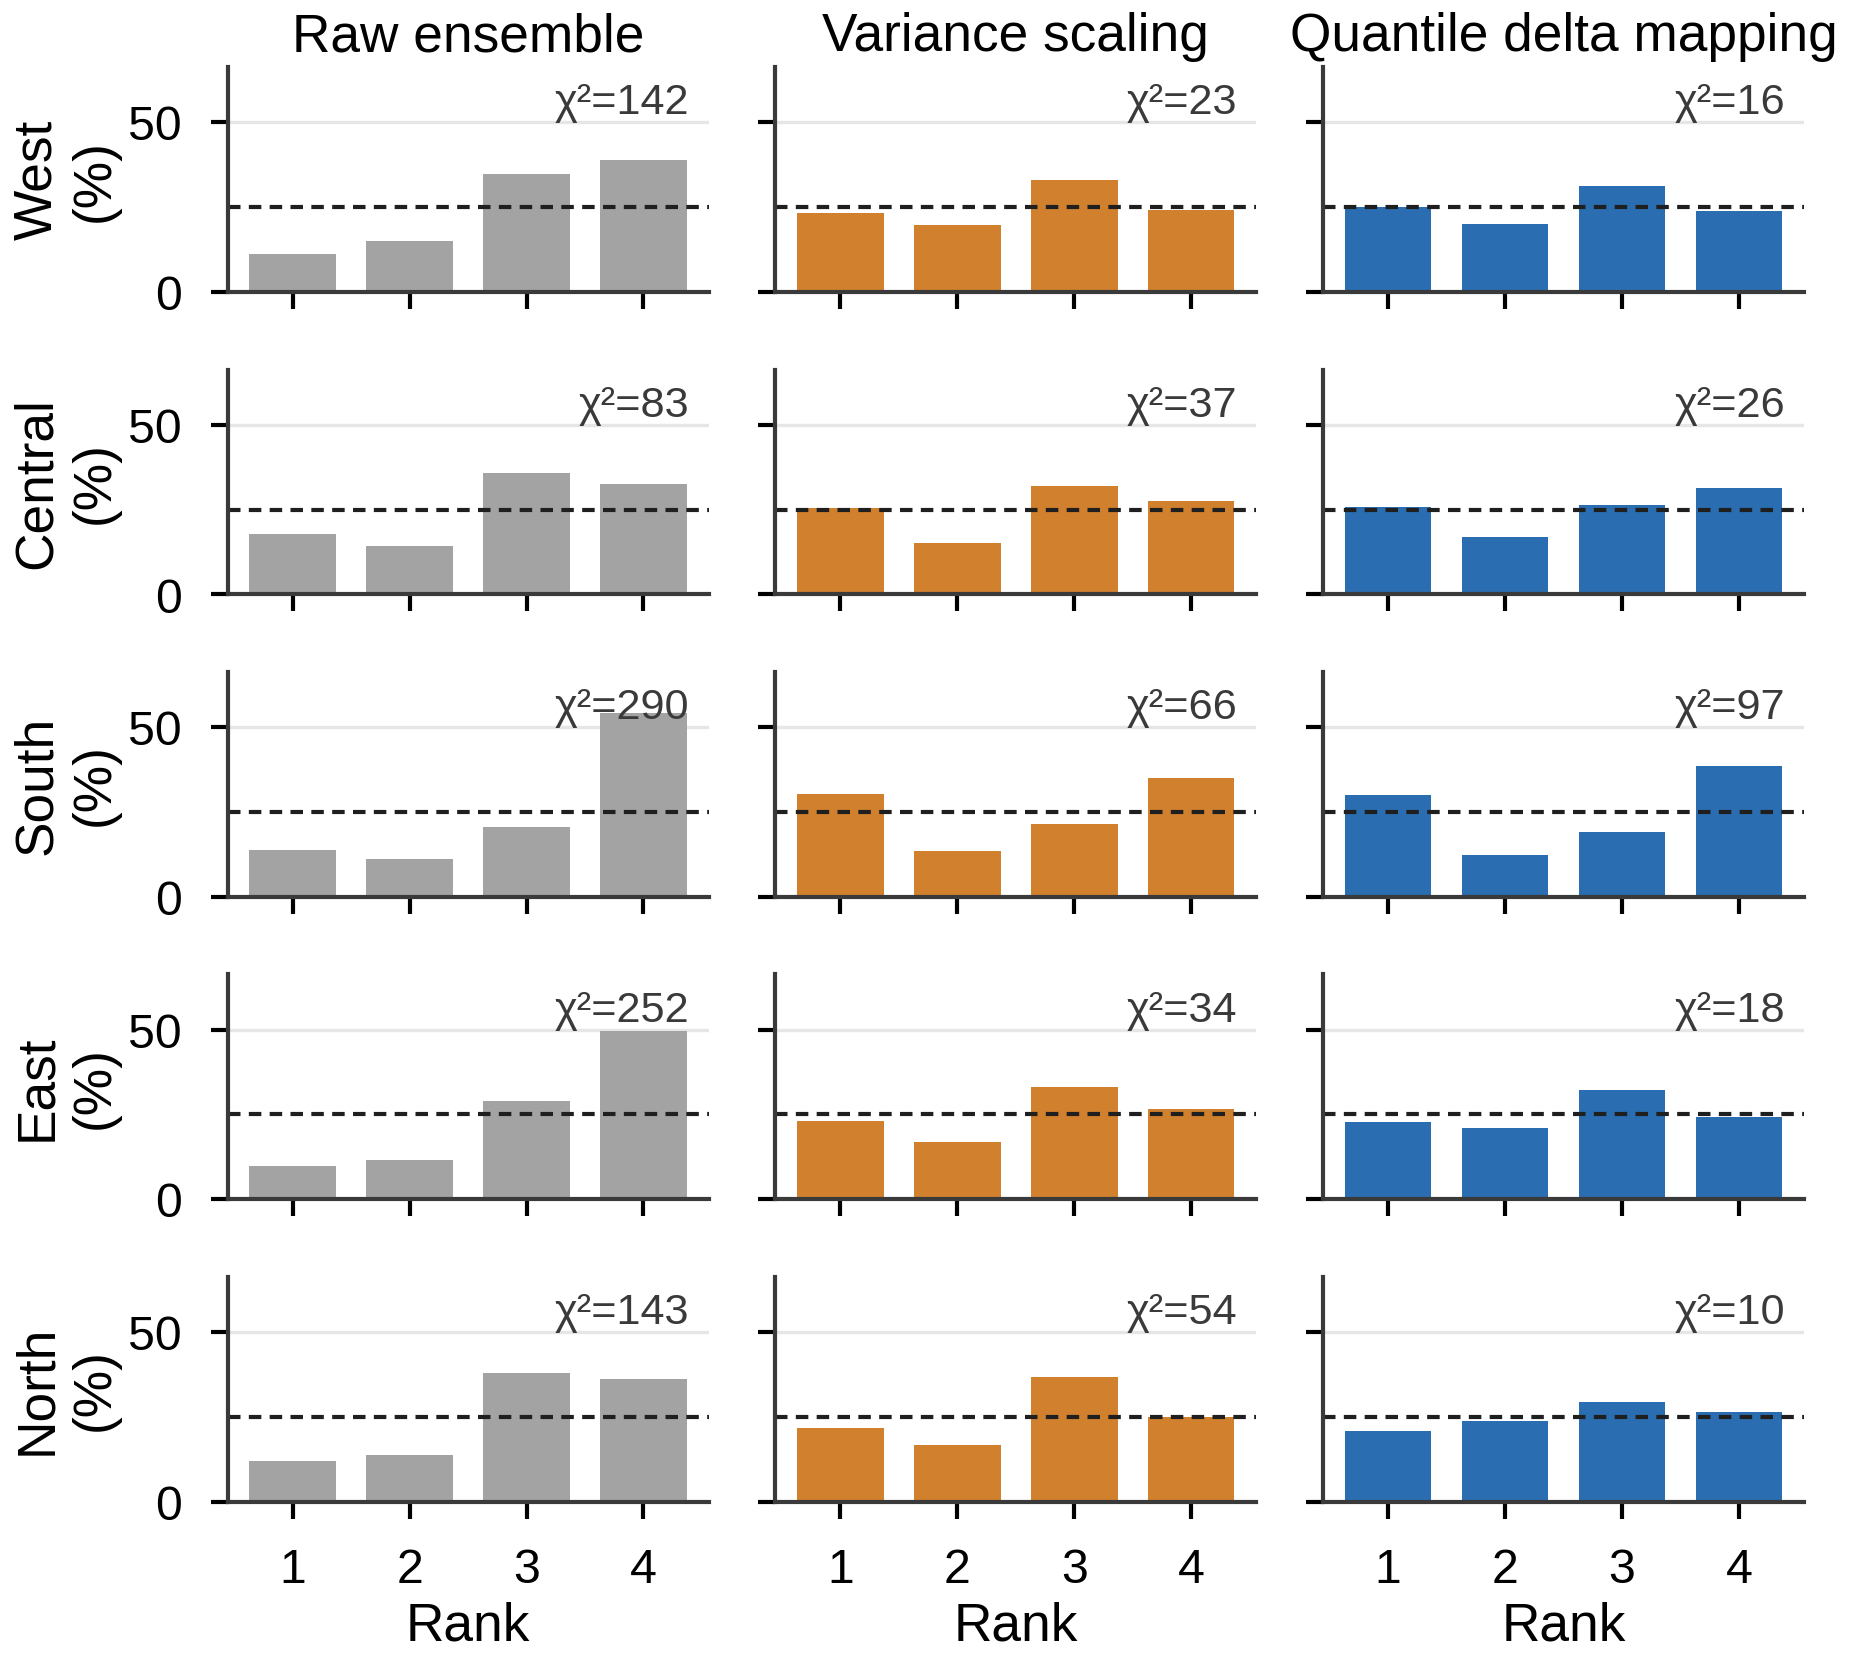

In [ ]:
v = validation.round(4).xs('All', level='season')
K = M + 1
fig, axes = plt.subplots(5, 3, figsize=(W, 3.2 * H), sharex=True, sharey=True)
ymax = v[[f'rank_{k}_pct' for k in range(1, K + 1)]].values.max() * 1.22
for i, p in enumerate(PROV):
    for j, name in enumerate(METHODS):
        ax = axes[i, j]; r = v.loc[(p, name)]
        ax.bar(range(1, K + 1), [r[f'rank_{k}_pct'] for k in range(1, K + 1)], color=COLOR[name], width=0.74)
        ax.axhline(100 / K, color='#1f1f1f', lw=0.5, ls=(0, (3, 2))); grid(ax); ax.set_ylim(0, ymax); ax.set_xticks(range(1, K + 1))
        ax.text(0.96, 0.93, f'χ²={r.chi2_total:.0f}', transform=ax.transAxes, ha='right', va='top', fontsize=5.2, color='#3a3a3a')
        if i == 0:
            ax.set_title(LABEL[name], pad=2, fontsize=6.4)
        if j == 0:
            ax.set_ylabel(f'{SHORT[p]}\n(%)', labelpad=1)
        if i == 4:
            ax.set_xlabel('Rank', labelpad=1)
save_figure(fig, 'Figure5')

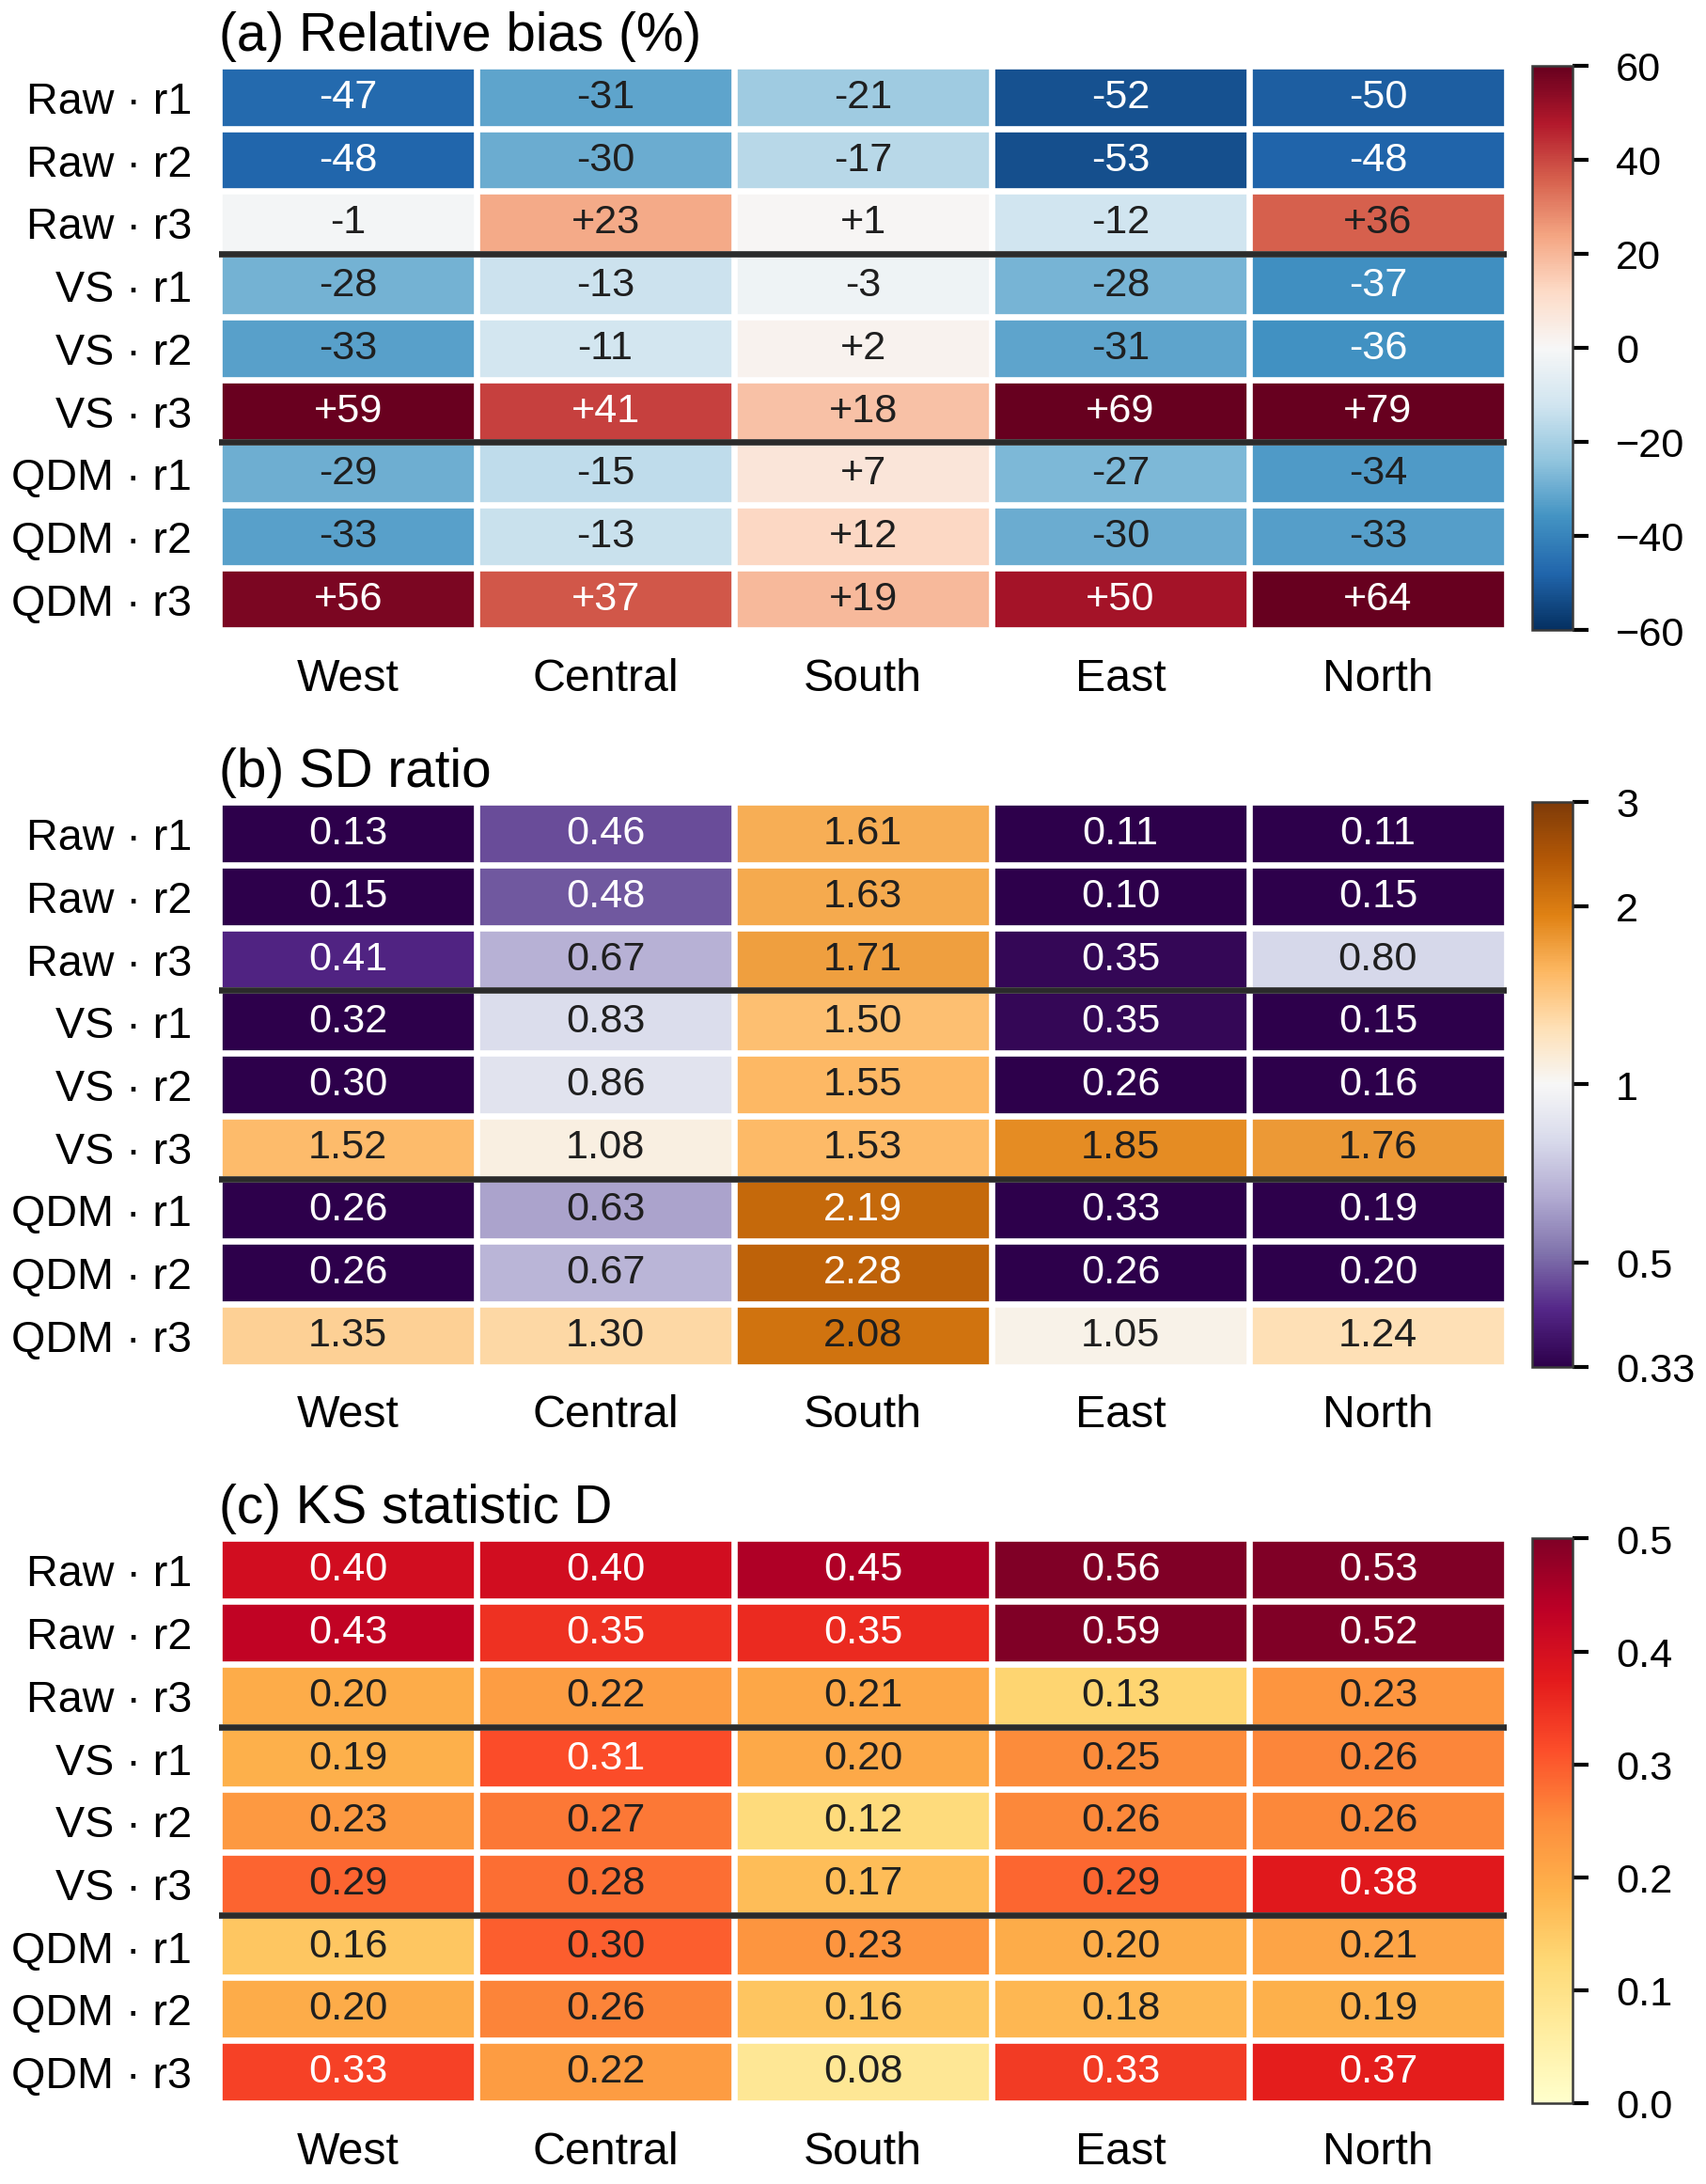

       rel_bias_pct        sd_ratio        ks_d      
                min    max      min   max   min   max
method                                               
QDM          -33.84  63.59     0.19  2.28  0.08  0.37
Raw          -52.76  35.76     0.10  1.71  0.13  0.59
VS           -36.68  79.46     0.15  1.85  0.12  0.38


In [ ]:
rows = []
for name, E in ENS.items():
    for p in PROV:
        m = (cal.province == p).values; y = cal.merra2.values[m]
        for j, c in enumerate(MEMBERS):
            x = E[m, j]
            rows.append({'method': name, 'province': p, 'member': c,
                         'rel_bias_pct': (x.mean() - y.mean()) / y.mean() * 100,
                         'sd_ratio': x.std(ddof=1) / y.std(ddof=1),
                         'ks_d': stats.ks_2samp(x, y).statistic})
member_diag = pd.DataFrame(rows)
per_member = save_table(member_diag.round(3), 'member_diagnostics', index=False)

METRICS = [('rel_bias_pct', 'Relative bias (%)', 'RdBu_r', matplotlib.colors.TwoSlopeNorm(vmin=-60, vcenter=0, vmax=60), '{:+.0f}'),
           ('sd_ratio', 'SD ratio', 'PuOr_r', matplotlib.colors.LogNorm(vmin=1 / 3, vmax=3), '{:.2f}'),
           ('ks_d', 'KS statistic D', 'YlOrRd', matplotlib.colors.Normalize(vmin=0, vmax=0.5), '{:.2f}')]
ABBR = {'Raw': 'Raw', 'VS': 'VS', 'QDM': 'QDM'}
rows = [(m, c) for m in METHODS for c in MEMBERS]
fig, axes = plt.subplots(3, 1, figsize=(W, 4.45 * H), sharex=True)
for ax, (col, title, cmap, norm, fmt), letter in zip(axes, METRICS, 'abc'):
    A = np.array([[per_member[(per_member.method == m) & (per_member.member == c) & (per_member.province == p)][col].iloc[0]
                   for p in PROV] for m, c in rows])
    im = ax.imshow(A, cmap=cmap, norm=norm, aspect='auto')
    for (a, b), val in np.ndenumerate(A):
        rgba = im.cmap(im.norm(val)); lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
        ax.text(b, a, fmt.format(val), ha='center', va='center', fontsize=5.2, color='white' if lum < 0.5 else '#1f1f1f')
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([f'{ABBR[m]} · {c}' for m, c in rows], fontsize=5.6)
    ax.set_xticks(range(5)); ax.set_xticklabels([SHORT[p] for p in PROV], fontsize=5.8); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks(np.arange(-0.5, 5), minor=True); ax.set_yticks(np.arange(-0.5, len(rows)), minor=True)
    ax.grid(which='minor', color='white', lw=0.8); ax.tick_params(which='minor', length=0)
    for yb in (2.5, 5.5):
        ax.axhline(yb, color='#2b2b2b', lw=0.8)
    panel_title(ax, letter, title); ax.tick_params(labelbottom=True)
    cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02, aspect=14); cb.ax.tick_params(labelsize=5.2); cb.outline.set_linewidth(0.3)
    if col == 'sd_ratio':
        cb.ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
        cb.set_ticks([1 / 3, 0.5, 1, 2, 3]); cb.set_ticklabels(['0.33', '0.5', '1', '2', '3'])
save_figure(fig, 'Figure6')
print(member_diag.groupby('method')[['rel_bias_pct', 'sd_ratio', 'ks_d']].agg(['min', 'max']).round(2).to_string())

## 8. Calibrated Projection

In [ ]:
k_vs, k_qdm = calibrate(cal, proj)
CALIB = k_qdm if SELECTED == 'QDM' else k_vs
result = proj[['date', 'province', 'month', 'season']].copy()
for i, c in enumerate(MEMBERS):
    result[f'{c}_raw'] = proj[c].values
    result[f'{c}_calibrated'] = CALIB[:, i]
result['ens_mean'] = CALIB.mean(1); result['ens_min'] = CALIB.min(1); result['ens_max'] = CALIB.max(1)
result['merra2'] = proj.merra2.values
result.to_csv(os.path.join(OUT_TAB, 'calibrated_daily_pm25.csv'), index=False)
assert not result[[f'{c}_calibrated' for c in MEMBERS]].isna().any().any()

target = result[result.date >= START_TARGET].copy()
monthly = target.groupby(['province', 'month']).ens_mean.mean().unstack('month').loc[PROV]
period = target.groupby('province').agg(period_mean=('ens_mean', 'mean')).loc[PROV]
member_period = target.groupby('province')[[f'{c}_calibrated' for c in MEMBERS]].mean().loc[PROV]
period['lowest_member'] = member_period.min(axis=1); period['highest_member'] = member_period.max(axis=1)
print('Method applied:', SELECTED)
print(f'Calibrated PM2.5, {date_text(START_TARGET)} – {date_text(proj.date.max())} (µg m-3)')
pd.concat([monthly, period], axis=1).round(1)

Method applied: QDM
Calibrated PM2.5, 1 September 2026 – 31 January 2027 (µg m-3)


,2026-09,2026-10,2026-11,2026-12,2027-01,period_mean,lowest_member,highest_member
province,,,,,,,,
West Kalimantan,20.3,9.9,3.2,4.7,5.5,8.7,5.3,15.2
Central Kalimantan,32.7,13.3,3.2,3.9,4.4,11.4,9.9,14.2
South Kalimantan,37.4,15.7,4.8,4.5,5.3,13.5,12.9,14.2
East Kalimantan,14.0,8.3,3.1,4.2,4.3,6.7,4.8,10.5
North Kalimantan,9.3,5.1,2.0,2.5,3.4,4.4,2.8,7.5


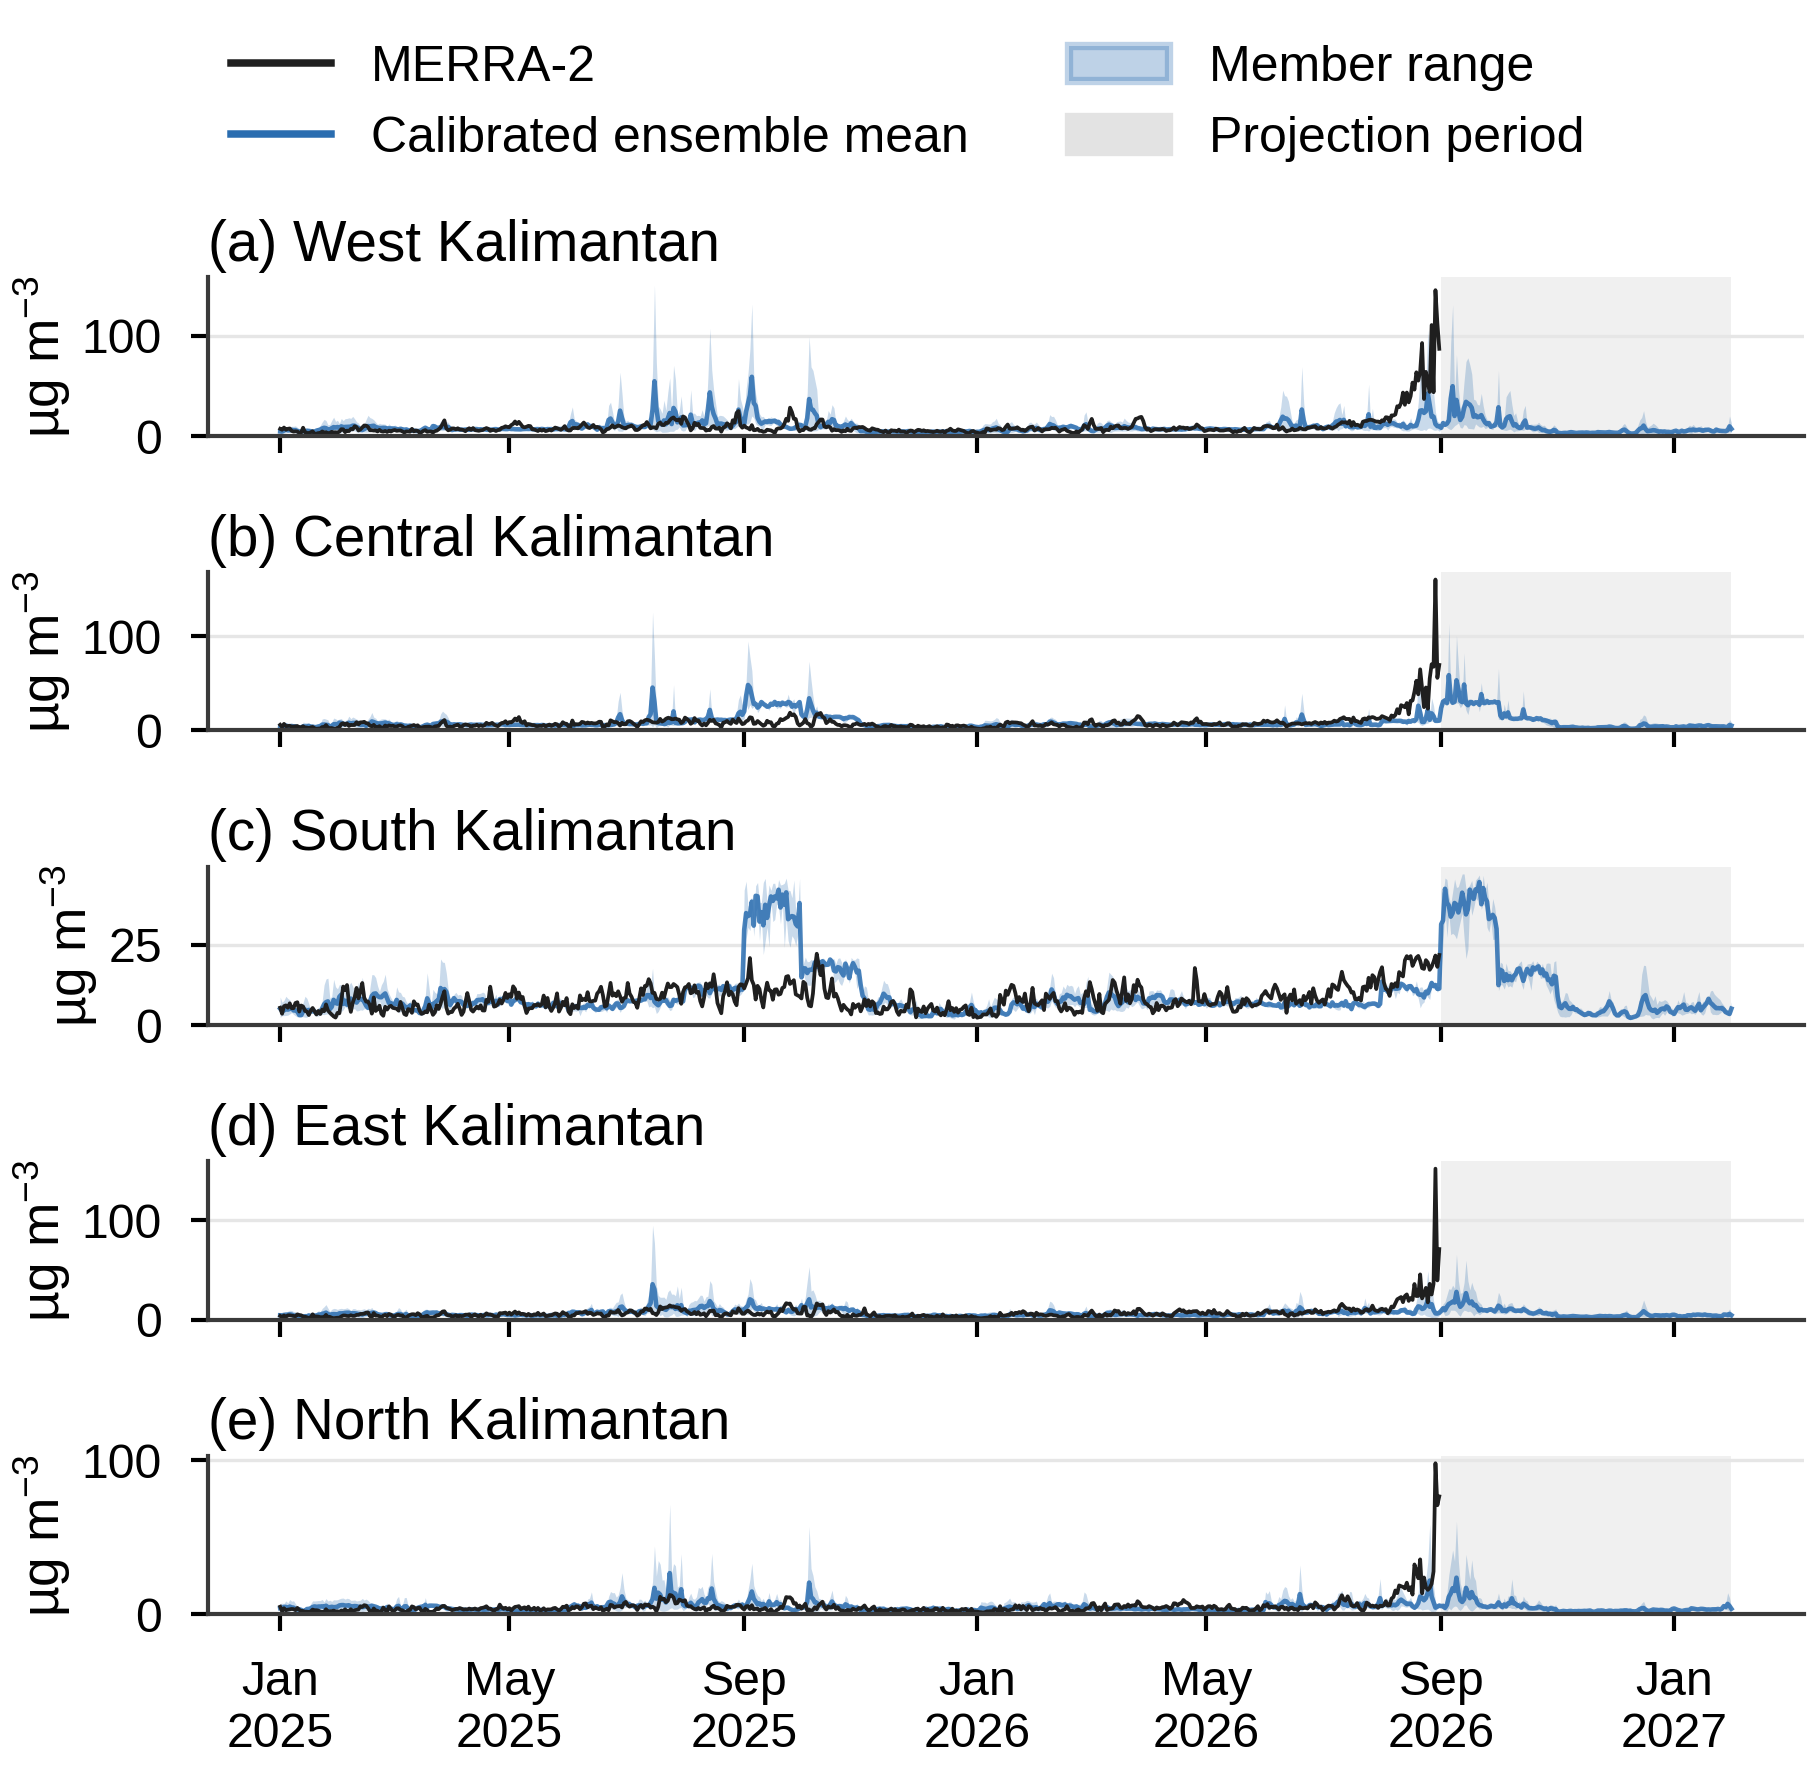

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(W, 3.4 * H), sharex=True)
for ax, p, letter in zip(axes, PROV, 'abcde'):
    d = result[result.province == p]
    ax.axvspan(START_TARGET, d.date.max(), color='#f0f0f0', lw=0, zorder=0)
    ax.fill_between(d.date, d.ens_min, d.ens_max, color=COLOR['QDM'], alpha=0.25, lw=0)
    ax.plot(d.date, d.ens_mean, color=COLOR['QDM'], lw=0.55, alpha=0.85)
    ax.plot(d.date, d.merra2, color=COLOR['MERRA-2'], lw=0.45)
    panel_title(ax, letter, p); grid(ax); ax.set_ylim(bottom=0); ax.set_ylabel('µg m$^{-3}$', labelpad=1)
date_axis(axes[-1])
fig.legend([plt.Line2D([], [], color=COLOR['MERRA-2'], lw=0.9), plt.Line2D([], [], color=COLOR['QDM'], lw=0.9),
            matplotlib.patches.Patch(color=COLOR['QDM'], alpha=0.3), matplotlib.patches.Patch(color='#e3e3e3')],
           ['MERRA-2', 'Calibrated ensemble mean', 'Member range', 'Projection period'], loc='outside upper center', ncol=2)
save_figure(fig, 'Figure7')

## 9. Air Quality Categories

In [ ]:
def category(x):
    return np.digitize(x, CAT_LIMITS, right=True)


cat = result[['date', 'province', 'month']].copy()
for c in MEMBERS:
    cat[c] = category(result[f'{c}_calibrated'].values)
for k, nm in enumerate(CAT_NAMES):
    cat[f'prob_{nm.lower().replace(" ", "_")}'] = (cat[MEMBERS] == k).mean(1)
cat['prob_above_standard'] = (result[[f'{c}_calibrated' for c in MEMBERS]].values > STANDARD_24H).mean(1)
cat.to_csv(os.path.join(OUT_TAB, 'daily_category_probability.csv'), index=False)

ct = cat[cat.date >= START_TARGET]
rows = []
for (p, b), d in ct.groupby(['province', 'month']):
    r = {'province': p, 'month': b}
    for k, nm in enumerate(CAT_NAMES):
        days = (d[MEMBERS] == k).sum(0); key = nm.lower().replace(' ', '_')
        r[f'days_{key}'] = days.mean(); r[f'days_{key}_min'] = days.min(); r[f'days_{key}_max'] = days.max()
    r['pct_member_days_above_55'] = d.prob_above_standard.mean() * 100
    r['any_member_above_55'] = bool((d.prob_above_standard > 0).any())
    rows.append(r)
cat_days = save_table(pd.DataFrame(rows).set_index(['province', 'month']).loc[PROV].round(2), 'projection_category_days')

obs = cal.copy(); obs['k'] = category(obs.merra2.values)
freq = (obs.groupby('province').k.value_counts(normalize=True).unstack(fill_value=0)
        .reindex(columns=range(5), fill_value=0).loc[PROV] * 100)
freq.columns = CAT_NAMES
save_table(freq.round(2), 'merra2_category_frequency')
print('MERRA-2 category frequency, calibration period (% of days):')
print(freq.round(1).to_string())
cat_days[['days_good', 'days_moderate', 'days_unhealthy', 'pct_member_days_above_55']].round(1)

MERRA-2 category frequency, calibration period (% of days):
                    Good  Moderate  Unhealthy  Very unhealthy  Hazardous
province                                                                
West Kalimantan     91.0       7.7        1.3             0.0          0
Central Kalimantan  94.9       4.1        0.8             0.2          0
South Kalimantan    94.6       5.4        0.0             0.0          0
East Kalimantan     95.2       4.4        0.2             0.2          0
North Kalimantan    96.7       2.8        0.5             0.0          0


days_good  days_moderate  days_unhealthy  \
province           month                                               
West Kalimantan    2026-09       20.7            7.0             2.3   
                   2026-10       27.7            3.0             0.3   
                   2026-11       30.0            0.0             0.0   
                   2026-12       30.0            1.0             0.0   
                   2027-01       30.7            0.3             0.0   
Central Kalimantan 2026-09        0.3           28.3             1.3   
                   2026-10       28.7            2.0             0.3   
                   2026-11       30.0            0.0             0.0   
                   2026-12       30.7            0.3             0.0   
                   2027-01       31.0            0.0             0.0   
South Kalimantan   2026-09        0.0           30.0             0.0   
                   2026-10       13.3           17.7             0.0   
                   2026-11       30.0            0.0             0.0   
                   2026-12       30.0            1.0             0.0   
                   2027-01       31.0            0.0             0.0   
East Kalimantan    2026-09       23.0            6.3             0.7   
                   2026-10       28.7            2.3             0.0   
                   2026-11       30.0            0.0             0.0   
                   2026-12       30.7            0.3             0.0   
                   2027-01       31.0            0.0             0.0   
North Kalimantan   2026-09       25.3            4.3             0.3   
                   2026-10       30.7            0.3             0.0   
                   2026-11       30.0            0.0             0.0   
                   2026-12       31.0            0.0             0.0   
                   2027-01       31.0            0.0             0.0   

                            pct_member_days_above_55  
province           month                              
West Kalimantan    2026-09                       7.8  
                   2026-10                       1.1  
                   2026-11                       0.0  
                   2026-12                       0.0  
                   2027-01                       0.0  
Central Kalimantan 2026-09                       4.4  
                   2026-10                       1.1  
                   2026-11                       0.0  
                   2026-12                       0.0  
                   2027-01                       0.0  
South Kalimantan   2026-09                       0.0  
                   2026-10                       0.0  
                   2026-11                       0.0  
                   2026-12                       0.0  
                   2027-01                       0.0  
East Kalimantan    2026-09                       2.2  
                   2026-10                       0.0  
                   2026-11                       0.0  
                   2026-12                       0.0  
                   2027-01                       0.0  
North Kalimantan   2026-09                       1.1  
                   2026-10                       0.0  
                   2026-11                       0.0  
                   2026-12                       0.0  
                   2027-01                       0.0

## 10. Monthly Maps of the Projection

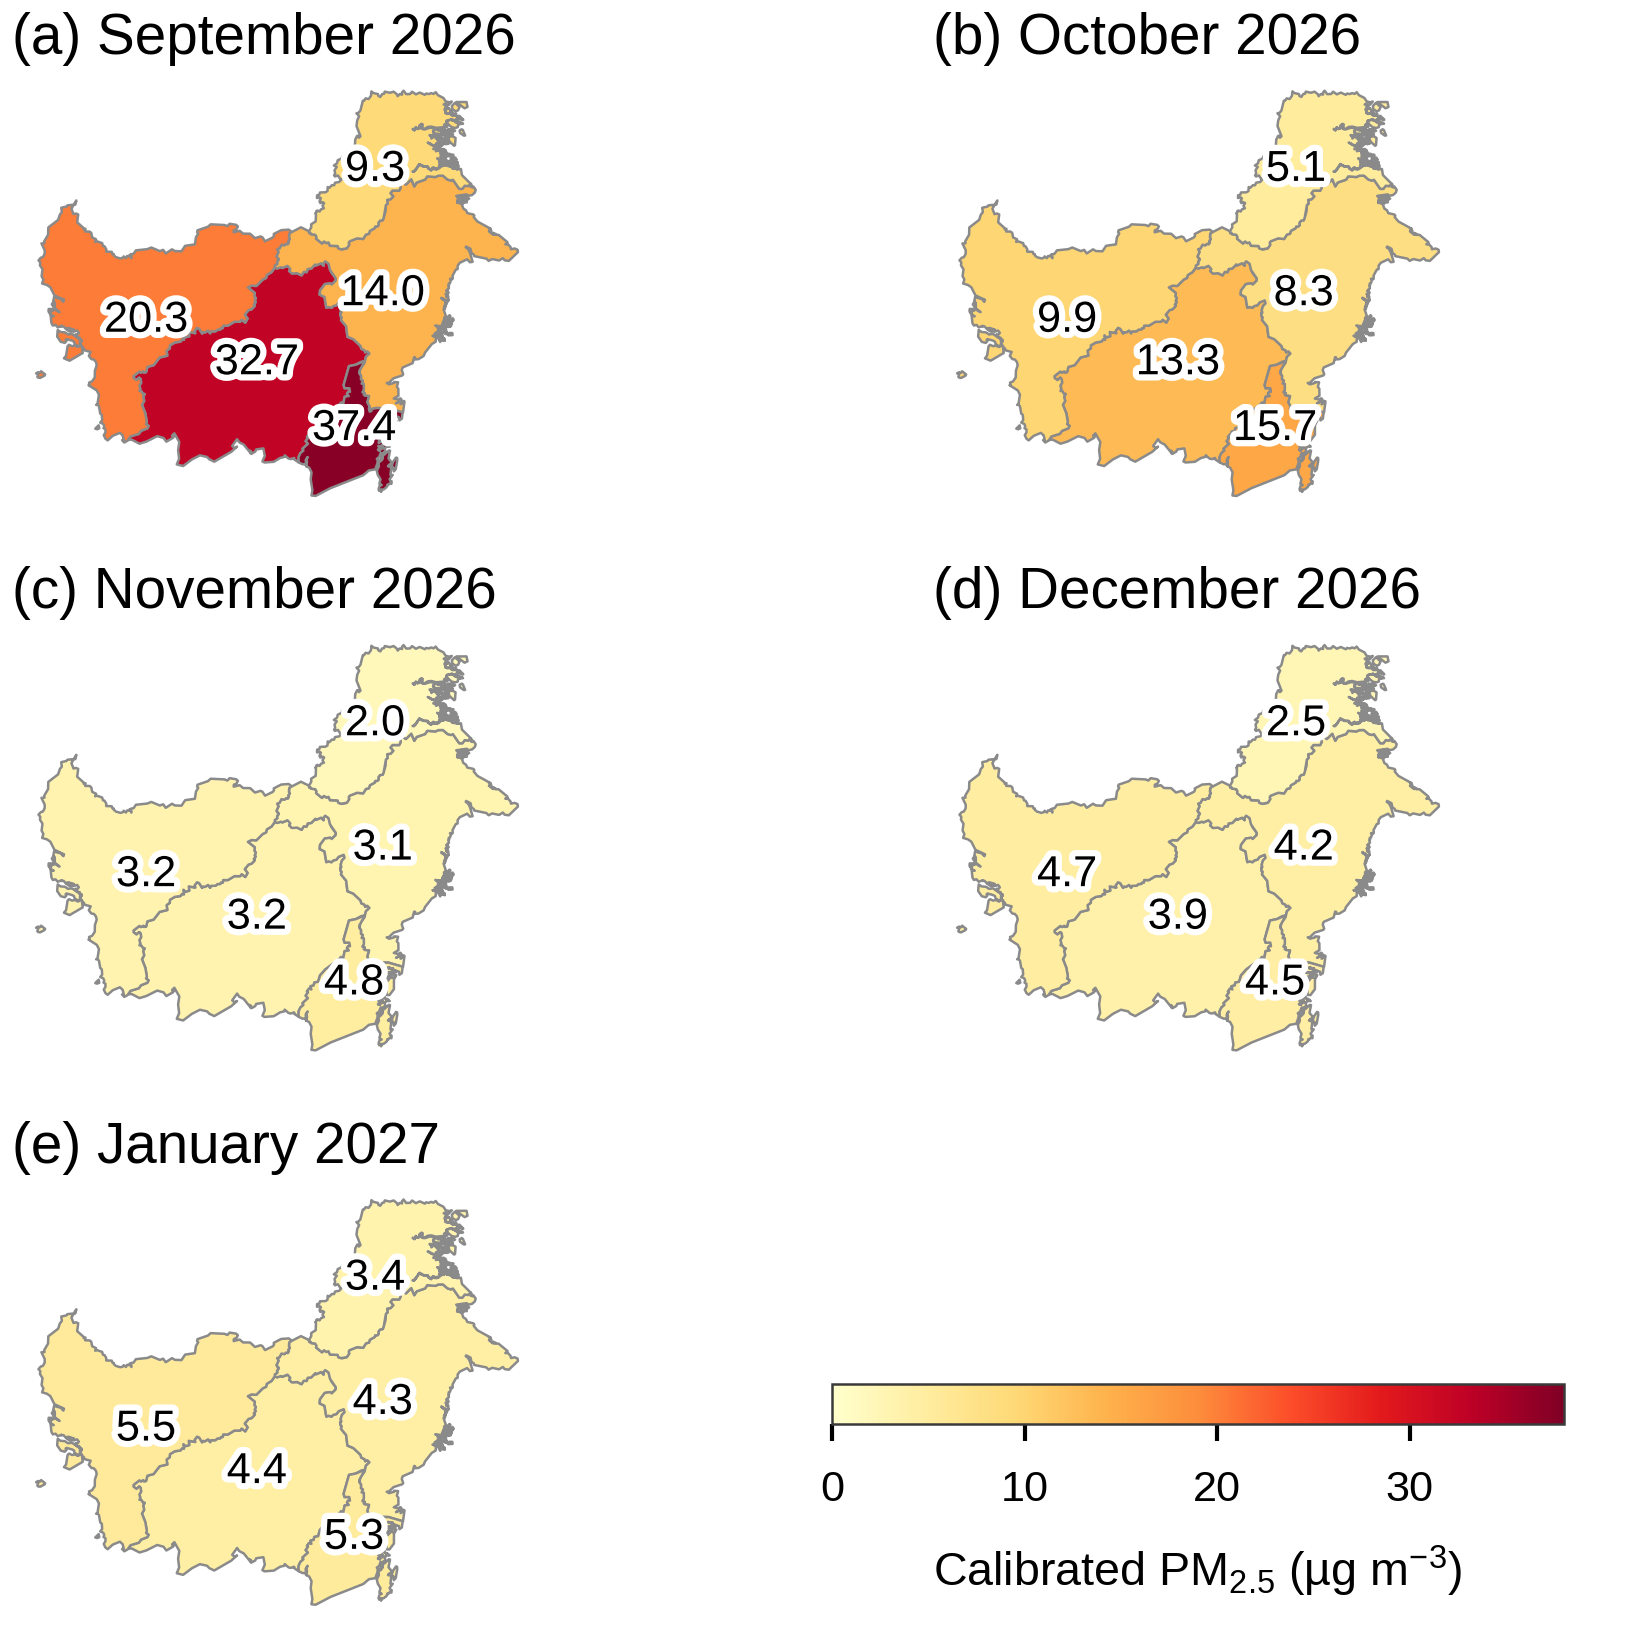

In [ ]:
mm = target.groupby(['province', 'month']).ens_mean.mean().reset_index()
months = sorted(mm.month.unique())
fig, axes = plt.subplots(3, 2, figsize=(W, 3.15 * H))
norm = matplotlib.colors.Normalize(0, np.ceil(mm.ens_mean.max()))
pt = {p: kal[kal.province == p].geometry.iloc[0].representative_point() for p in PROV}
for ax, b, letter in zip(axes.flat, months, 'abcde'):
    gg = kal.merge(mm[mm.month == b], on='province')
    gg.plot(column='ens_mean', ax=ax, cmap='YlOrRd', norm=norm, edgecolor='#8a8a8a', lw=0.3)
    for _, r in gg.iterrows():
        c = pt[r.province]
        ax.text(c.x, c.y, f'{r.ens_mean:.1f}', ha='center', va='center', fontsize=5.2,
                path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])
    panel_title(ax, letter, f'{MONTHS_LONG[int(b[5:]) - 1]} {b[:4]}'); ax.set_axis_off(); ax.set_aspect('equal')
axes.flat[5].set_axis_off()
cax = axes.flat[5].inset_axes([0.08, 0.45, 0.84, 0.09])
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='YlOrRd'), cax=cax, orientation='horizontal')
cb.set_label('Calibrated ' + UNIT, fontsize=5.6); cb.ax.tick_params(labelsize=5.2); cb.outline.set_linewidth(0.3)
save_figure(fig, 'Figure8')

## 11. Composition of MERRA-2 PM2.5

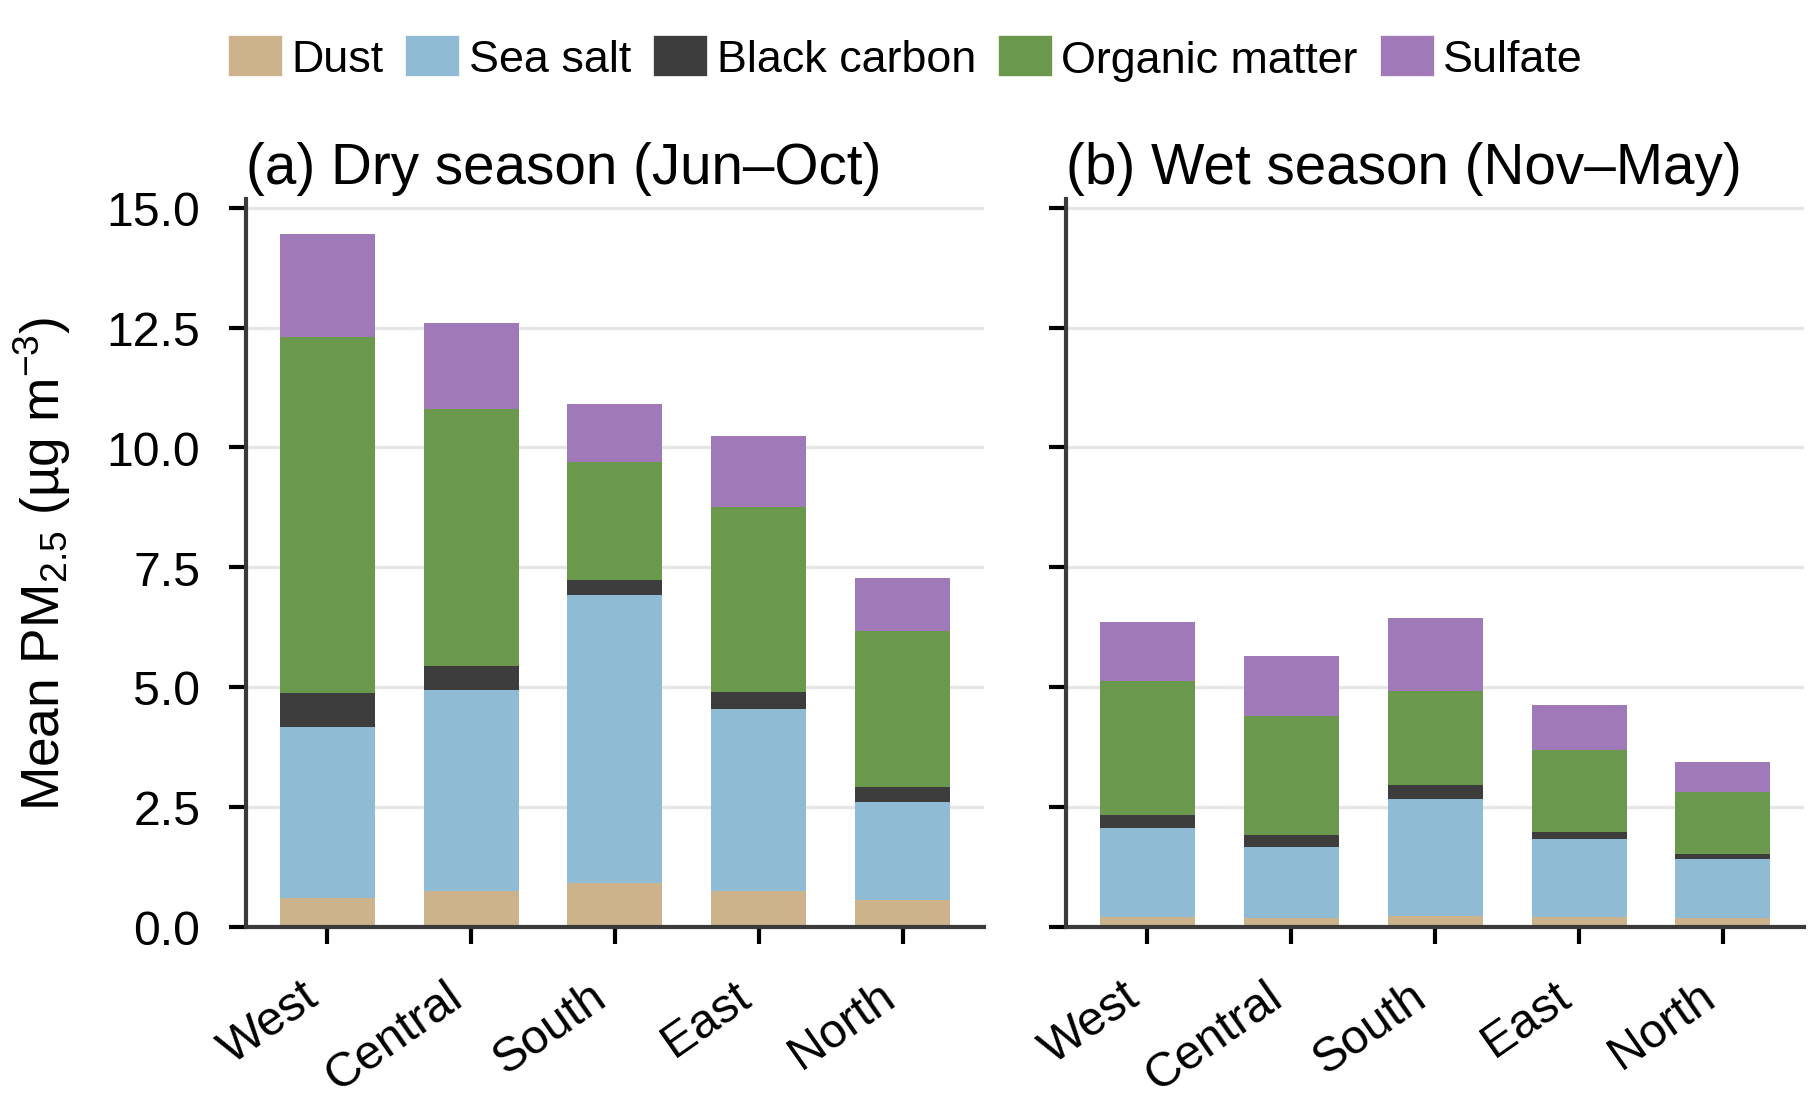

Share of each component on the 10 days with the highest PM2.5 (%):
                    Dust  Sea salt  Black carbon  Organic matter  Sulfate
province                                                                 
West Kalimantan      0.7      12.3           6.5            68.6     11.9
Central Kalimantan   0.9      14.5           6.4            68.6      9.7
South Kalimantan     5.8      52.3           3.0            31.5      7.4
East Kalimantan      1.4      19.3           5.9            62.4     11.1
North Kalimantan     1.2      14.1           6.4            66.6     11.8


In [ ]:
COMP = ['dust', 'sea_salt', 'black_carbon', 'organic_matter', 'sulfate']
COMP_LABEL = ['Dust', 'Sea salt', 'Black carbon', 'Organic matter', 'Sulfate']
COMP_COLOR = ['#cdb38b', '#8fbcd4', '#3d3d3d', '#6a994e', '#a07ab8']
comp = pd.read_csv(F_COMP, parse_dates=['date'])
comp['season'] = season_of(comp.date)
rows = []
for p in PROV:
    d = comp[comp.province == p]
    for s in ['Dry', 'Wet']:
        r = d[d.season == s][COMP].mean(); r['province'], r['season'] = p, s; rows.append(r)
    top = d.nlargest(10, 'pm25_total')
    r = top[COMP].sum() / top.pm25_total.sum(); r['province'], r['season'] = p, 'top_10_days'; rows.append(r)
components_full = pd.DataFrame(rows).set_index(['province', 'season'])
components = save_table(components_full.round(4), 'merra2_components')

fig, axes = plt.subplots(1, 2, figsize=(W, 2.15 * H), sharey=True)
for ax, s, letter, title in zip(axes, ['Dry', 'Wet'], 'ab', ['Dry season (Jun–Oct)', 'Wet season (Nov–May)']):
    t = components.xs(s, level='season').reindex(PROV); bottom = np.zeros(5)
    for k, c in zip(COMP, COMP_COLOR):
        ax.bar(range(5), t[k].values, bottom=bottom, color=c, width=0.66, lw=0); bottom += t[k].values
    ax.set_xticks(range(5)); ax.set_xticklabels([SHORT[p] for p in PROV], rotation=35, ha='right')
    panel_title(ax, letter, title); grid(ax)
axes[0].set_ylabel('Mean ' + UNIT)
fig.legend([matplotlib.patches.Patch(color=c) for c in COMP_COLOR], COMP_LABEL, loc='outside upper center', ncol=5,
           handlelength=1, columnspacing=0.6, handletextpad=0.3, fontsize=5.4)
save_figure(fig, 'Figure9')
share = components_full.xs('top_10_days', level='season')[COMP] * 100
share.columns = COMP_LABEL
print('Share of each component on the 10 days with the highest PM2.5 (%):')
print(share.round(1).to_string())

## 12. Summary

In [ ]:
print(f'Calibration period : {date_text(cal.date.min())} – {date_text(cal.date.max())} ({cal.date.nunique()} days, {len(CAL_MONTHS)} months)')
print(f'Projection period  : {date_text(START_TARGET)} – {date_text(proj.date.max())}')
print()
print(f'Synchrony test (daily anomaly correlation): {synchrony.anomaly_correlation.min():.2f} to '
      f'{synchrony.anomaly_correlation.max():.2f}; maximum R2 {synchrony.anomaly_r2_pct.max():.1f}%')
print()
print('Leave-one-month-out validation, all provinces:')
for m, r in summary.iterrows():
    print(f'  {m:4s} KS D = {r.ks_d_mean_province:.3f}  chi2 = {r.chi2_rank_histogram:6.1f}  bias = {r.bias:+.2f}  '
          f'SD ratio = {r.sd_ratio:.2f}  CRPS = {r.crps:.3f}')
print(f'  Selected method: {SELECTED}')
print()
print('Calibrated PM2.5 over the projection period (µg m-3):')
for p, r in period.iterrows():
    print(f'  {p:19s} {r.period_mean:5.1f}  (member means {r.lowest_member:.1f}–{r.highest_member:.1f})')

Calibration period : 1 January 2025 – 31 August 2026 (608 days, 20 months)
Projection period  : 1 September 2026 – 31 January 2027

Synchrony test (daily anomaly correlation): -0.06 to 0.09; maximum R2 0.8%

Leave-one-month-out validation, all provinces:
  Raw  KS D = 0.275  chi2 =  766.4  bias = -1.78  SD ratio = 0.56  CRPS = 2.950
  VS   KS D = 0.085  chi2 =  146.6  bias = +0.24  SD ratio = 1.05  CRPS = 2.818
  QDM  KS D = 0.079  chi2 =   74.4  bias = +0.18  SD ratio = 0.96  CRPS = 2.920
  Selected method: QDM

Calibrated PM2.5 over the projection period (µg m-3):
  West Kalimantan       8.7  (member means 5.3–15.2)
  Central Kalimantan   11.4  (member means 9.9–14.2)
  South Kalimantan     13.5  (member means 12.9–14.2)
  East Kalimantan       6.7  (member means 4.8–10.5)
  North Kalimantan      4.4  (member means 2.8–7.5)
